# Spatio-Temporal Sensor-Network Reconstruction — Full Project Notebook
## Cook Farm (CAF) soil-sensor dataset — portfolio project for the CRAN / INRS internship

This notebook is the continuation of the Stage-0 data-fetching notebook. It implements the full
pipeline we agreed on, narrowed to mirror the internship's own stated axes of work:

| # | Stage | Mirrors (internship wording) |
|---|---|---|
| 0 | Data fetching & raw inspection | — (prerequisite) |
| 1 | Cleaning, QC integration, synchronization, descriptive stats | "prétraitement et exploration... synchronisation, nettoyage, visualisation, analyse statistique" |
| 2 | Spatial structuring (geocoding, spatial join, the data cube, evaluation folds) | setup for spatio-temporal modelling |
| 3 | Spatial / temporal relationship exploration | "étude... des méthodes d'interpolation spatio-temporelle" |
| 4 | Reconstruction methods: Kriging, Tensor completion, Neural/PINN | "Krigeage, modèles tensoriels, réseaux de neurones informés par la physique" |
| 5 | Quantitative comparison | "évaluation quantitative des modèles" |
| 6 | Covariate / data fusion | "fusion de données multimodales" |
| 7 | Dynamic spatio-temporal visualization | "cartographies spatio-temporelles dynamiques" |
| 8 | Save the trained reconstruction system | prerequisite for the future web demo (not built in this notebook) |

**Everything here uses only free, open-source libraries** (pandas, numpy, scipy, scikit-learn,
geopandas, PyTorch, PyKrige, statsmodels, matplotlib) — no paid APIs, no licensed software.

**On the web demo:** stage 8 saves a clean, reusable "reconstruction system" (trained weights,
scalers, variogram config, tensor factors, a unified `reconstruct_field(...)` function) to disk.
That is deliberately as far as this notebook goes — the interactive web application that lets an
instructor click on a map, add sensors, and watch the reconstruction update is a **separate, later
task** that will *load* what Stage 8 produces. Building it now would mix concerns; the research
pipeline must stand on its own first.

**Compute note:** this is designed to run on a free Colab T4 GPU. To keep training fast, the
reconstruction methods (Stage 4 onward) are evaluated on a *stratified subset of dates* (spread
across all 9 years, not just the first chunk of the record) rather than on all 3,346 daily
timestamps — chosen to preserve spatial, depth and temporal coverage while staying light enough to
iterate on quickly. The full daily series is still used for Stages 1–3 (cleaning, structuring,
exploration), since those are cheap.


# STAGE 0 — Environment & Data Fetching
(Reused from the Stage-0 notebook. Run this section first — everything after it assumes `daily_all`, `metadata_dfs`, `flag_files`, `gdfs`, `DATA_ROOT`, `SAVE_DIR` exist.)

## 0.1 Runtime check (T4 GPU)

In [ ]:
import subprocess

print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

import torch
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device name:", torch.cuda.get_device_name(0))
print("Using device:", DEVICE)


Thu Oct  1 21:01:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 0.2 Install dependencies
All free / open-source (BSD or MIT licensed): geospatial stack + PyKrige (Kriging) + statsmodels (autocorrelation). PyTorch, pandas, numpy, scikit-learn are preinstalled on Colab.

In [ ]:
!pip install -q geopandas rasterio pyproj shapely fiona pykrige statsmodels


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 72.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 53.0 MB/s eta 0:00:00


## 0.3 Mount Drive & locate the dataset
Same as Stage 0: your full dataset folder (including the `.shp` sidecars `.shx`/`.dbf`/`.prj` and the raster `.tif` files) should already be unzipped in Drive from the earlier notebook.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = "/content/CookFarm"
SAVE_DIR = "/content/drive/MyDrive/CAF_Sensor_results"

import os, zipfile

DRIVE_ZIP_PATH = "/content/drive/MyDrive/CAF_Sensor_Dataset_2.zip"  # change if needed

if not os.path.isdir(DATA_ROOT) or not os.listdir(DATA_ROOT):
    if os.path.exists(DRIVE_ZIP_PATH):
        os.makedirs(DATA_ROOT, exist_ok=True)
        with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zf:
            zf.extractall(DATA_ROOT)
        print(f"Extracted {DRIVE_ZIP_PATH} -> {DATA_ROOT}")
    else:
        print(f"WARNING: {DATA_ROOT} is empty and {DRIVE_ZIP_PATH} was not found.")
        print("Fix DATA_ROOT / DRIVE_ZIP_PATH before continuing.")
else:
    print(f"Using existing data at {DATA_ROOT}")

os.makedirs(SAVE_DIR, exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracted /content/drive/MyDrive/CAF_Sensor_Dataset_2.zip -> /content/CookFarm


## 0.4 Helper functions

In [ ]:
import glob
import re
import pandas as pd
import numpy as np

def find_files(pattern, root=None):
    root = root or DATA_ROOT
    return sorted(glob.glob(os.path.join(root, "**", pattern), recursive=True))

def try_read_table(path, **kwargs):
    try:
        return pd.read_csv(path, sep=None, engine="python", **kwargs)
    except Exception as e:
        print(f"pd.read_csv auto-detect failed for {path}: {e}")
        return None


## 0.5 Load the daily sensor series

In [ ]:
all_txt = find_files("*.txt")

def is_location_file(path):
    return re.match(r"^CAF\d{3}\.txt$", os.path.basename(path), re.IGNORECASE) is not None

daily_sensor_files = [f for f in all_txt if is_location_file(f) and "daily" in f.lower()]
if not daily_sensor_files:
    daily_sensor_files = [f for f in all_txt if is_location_file(f)]
    print("No 'daily' folder filter matched — using all CAFxxx.txt files found. "
          "If your Daily/Hourly split lives in different folder names, adjust the filter above.")

daily_dfs = []
for f in daily_sensor_files:
    df = try_read_table(f)
    if df is not None:
        df["__source_file"] = os.path.basename(f)
        if "Location" not in df.columns:
            df["Location"] = os.path.basename(f).replace(".txt", "").upper()
        daily_dfs.append(df)

daily_all = pd.concat(daily_dfs, ignore_index=True)
daily_all["Date"] = pd.to_datetime(daily_all["Date"])
print("daily_all shape:", daily_all.shape)
print("locations:", daily_all["Location"].nunique())
print("date range:", daily_all["Date"].min(), "-", daily_all["Date"].max())
daily_all.head()


daily_all shape: (140532, 13)
locations: 42
date range: 2007-04-20 00:00:00 - 2016-06-16 00:00:00


,Location,Date,VW_30cm,VW_60cm,VW_90cm,VW_120cm,VW_150cm,T_30cm,T_60cm,T_90cm,T_120cm,T_150cm,__source_file
0,CAF003,2007-04-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAF003.txt
1,CAF003,2007-04-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAF003.txt
2,CAF003,2007-04-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAF003.txt
3,CAF003,2007-04-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAF003.txt
4,CAF003,2007-04-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAF003.txt


## 0.6 Load static metadata (bulk density, particle size, crop)

In [ ]:
metadata_targets = {
    "bulk_density": "CAF_BulkDensity.txt",
    "crop_id": "CAF_CropID.txt",
    "crop_codes": "CAF_CropCodes.txt",
    "particle_size": "CAF_ParticleSize.txt",
}

metadata_dfs = {}
for name, pattern in metadata_targets.items():
    matches = find_files(pattern)
    metadata_dfs[name] = try_read_table(matches[0]) if matches else None
    print(name, "->", "loaded" if metadata_dfs[name] is not None else "MISSING", matches)

# drop known empty Excel-artifact columns from crop_id, if present
if metadata_dfs["crop_id"] is not None:
    metadata_dfs["crop_id"] = metadata_dfs["crop_id"].loc[:, ~metadata_dfs["crop_id"].columns.str.startswith("Unnamed")]


bulk_density -> loaded ['/content/CookFarm/CAF_BulkDensity.txt']
crop_id -> loaded ['/content/CookFarm/CAF_CropID.txt']
crop_codes -> loaded ['/content/CookFarm/CAF_CropCodes.txt']
particle_size -> loaded ['/content/CookFarm/CAF_ParticleSize.txt']


## 0.7 Locate QC flag files
Content is parsed properly in Stage 1 — here we just locate them, as in Stage 0.

In [ ]:
flag_prefixes = ["missing", "range", "flats", "spikes", "breaks"]
flag_files = {p: find_files(f"{p}*") for p in flag_prefixes}
for p, files in flag_files.items():
    print(p, "->", len(files), "file(s)")


missing -> 10 file(s)
range -> 10 file(s)
flats -> 10 file(s)
spikes -> 5 file(s)
breaks -> 5 file(s)


## 0.8 Load spatial layers (sensors + strips)
These now load with their full attribute tables (`.dbf`), since the complete shapefile set is in your local dataset folder.

In [ ]:
import geopandas as gpd

gdfs = {}
for name, pattern in [("sensors", "CAF_sensors.shp"), ("strips", "CAF_strips.shp")]:
    matches = find_files(pattern)
    if not matches:
        print(f"{name}: NOT FOUND")
        gdfs[name] = None
        continue
    gdf = gpd.read_file(matches[0])
    print(f"=== {name} ===  CRS: {gdf.crs}  shape: {gdf.shape}  columns: {list(gdf.columns)}")
    gdfs[name] = gdf

if gdfs.get("sensors") is not None:
    display(gdfs["sensors"].head())
if gdfs.get("strips") is not None:
    display(gdfs["strips"].head())


=== sensors ===  CRS: EPSG:26911  shape: (42, 4)  columns: ['Location', 'Easting', 'Northing', 'geometry']
=== strips ===  CRS: EPSG:26911  shape: (20, 13)  columns: ['Strip', 'Field', 'Y2007', 'Y2008', 'Y2009', 'Y2010', 'Y2011', 'Y2012', 'Y2013', 'Y2014', 'Y2015', 'Y2016', 'geometry']


,Location,Easting,Northing,geometry
0,CAF003,493383,5180586,POINT (493384.052 5180585.318)
1,CAF007,493511,5180568,POINT (493512.052 5180567.318)
2,CAF009,493575,5180573,POINT (493576.052 5180572.318)
3,CAF019,493247,5180590,POINT (493248.052 5180589.318)
4,CAF031,493628,5180612,POINT (493629.052 5180611.318)


,Strip,Field,Y2007,Y2008,Y2009,Y2010,Y2011,Y2012,Y2013,Y2014,Y2015,Y2016,geometry
0,6,A,SB,SW,WW,SB,SW,WW,SB,SW,WW,SC,"POLYGON ((493384.735 5180566.56, 493787.332 51..."
1,5,A,SP,SW,WW,SL,SW,WW,SL,SW,SC,SC,"POLYGON ((493345.743 5180567.317, 493750.45 51..."
2,4,A,Fallow,SW,WW,SW,SL,WW,SW,SL,SL,WW,"POLYGON ((493307.189 5180568.433, 493706.264 5..."
3,3,A,SC,WC,WW,SW,SL,WW,SW,SL,WW,SC,"POLYGON ((493270.522 5180570.421, 493664.27 51..."
4,2,A,WL,SW,WW,SW,SL,WW,SW,SL,SC,SC,"POLYGON ((493231.205 5180571.525, 493599.634 5..."


# STAGE 1 — Cleaning, QC Integration, Synchronization & Descriptive Statistics

**Goal:** turn the raw daily table into one clean, analysis-ready spatio-temporal table, with an
explicit, inspectable missing-data mask — rather than silently dropping or imputing anything.

**Mirrors:** "prétraitement et exploration de données expérimentales multicapteurs : synchronisation,
nettoyage, visualisation et analyse statistique des mesures."

Steps:
- 1.1 — Parse dates, define the channel columns
- 1.2 — Parse the QC flag files and apply them as an explicit mask (additional to existing NaNs)
- 1.3 — Synchronization check (continuous daily calendar per location)
- 1.4 — Descriptive statistics & visualization


## 1.1 Channel columns & basic parsing

In [ ]:
VW_COLS = ["VW_30cm", "VW_60cm", "VW_90cm", "VW_120cm", "VW_150cm"]
T_COLS  = ["T_30cm", "T_60cm", "T_90cm", "T_120cm", "T_150cm"]
CHANNEL_COLS = VW_COLS + T_COLS
DEPTHS = [30, 60, 90, 120, 150]

daily_all = daily_all.sort_values(["Location", "Date"]).reset_index(drop=True)

print("Missing %% per channel BEFORE QC-flag masking:")
print((daily_all[CHANNEL_COLS].isna().mean() * 100).round(1))


Missing %% per channel BEFORE QC-flag masking:
VW_30cm     44.8
VW_60cm     46.5
VW_90cm     46.3
VW_120cm    46.1
VW_150cm    47.0
T_30cm      44.5
T_60cm      45.4
T_90cm      45.4
T_120cm     45.5
T_150cm     47.8
dtype: float64


## 1.2 Parse & apply the QC flag files

The flag files (`missing_*`, `range_*`, `flats_*`, `spikes_*`, `breaks_*`) mark, per location and
date(/time), readings that are missing, out-of-range, flat-lined, spiking, or breaking. Their exact
column layout can vary (a long `Location/Date/Flag` table, or a wide matrix with dates as rows and
locations as columns), so the loader below tries both and reports what it found — **check the
printed diagnostics after running this cell**; if a file reports 0 parsed flags, open its raw
preview (Stage 0 notebook, section 6) and adjust `load_flag_table` accordingly. This is the one
place in the whole pipeline most likely to need a manual tweak once you've actually looked at a
real flag file's layout.

This single cell defines the parser, collects every flagged `(Location, Date)` entry per channel,
and applies them as `NaN` on top of the existing raw missing values.

In [ ]:
def parse_flag_filename(path):
    """Map a flag filename (e.g. 'spikes_VW_30.txt', 'range_T_150.txt') to (category, column_name)."""
    base = os.path.basename(path)
    base_noext = os.path.splitext(base)[0]
    m = re.match(r"^(missing|range|flats|spikes|breaks)[_\-]?(VW|T)[_\-]?(\d+)", base_noext, re.IGNORECASE)
    if not m:
        return None, None
    category, var, depth = m.group(1).lower(), m.group(2).upper(), m.group(3)
    column = f"{var}_{depth}cm"
    return category, column


def load_flag_table(path):
    """Return a long DataFrame [Location, Date] of flagged entries, trying a couple of layouts."""
    df = try_read_table(path)
    if df is None or df.empty:
        return pd.DataFrame(columns=["Location", "Date"])

    cols_lower = [c.lower() for c in df.columns]

    # Layout A: long format with explicit Location + Date columns
    if "location" in cols_lower and ("date" in cols_lower):
        loc_col = df.columns[cols_lower.index("location")]
        date_col = df.columns[cols_lower.index("date")]
        out = df[[loc_col, date_col]].rename(columns={loc_col: "Location", date_col: "Date"})
        out["Date"] = pd.to_datetime(out["Date"], errors="coerce")
        out["Location"] = out["Location"].astype(str).str.upper().str.strip()
        return out.dropna(subset=["Date"])

    # Layout B: wide format — first column is Date, remaining columns are Location codes,
    # a non-null / non-empty cell means "flagged"
    first_col = df.columns[0]
    if "date" in first_col.lower() or re.match(r"\d{1,2}/\d{1,2}/\d{2,4}", str(df[first_col].iloc[0])):
        wide = df.rename(columns={first_col: "Date"})
        wide["Date"] = pd.to_datetime(wide["Date"], errors="coerce")
        value_cols = [c for c in wide.columns if c != "Date"]
        melted = wide.melt(id_vars="Date", value_vars=value_cols, var_name="Location", value_name="flag")
        melted["Location"] = melted["Location"].astype(str).str.upper().str.strip()
        melted = melted[melted["flag"].notna() & (melted["flag"].astype(str).str.strip() != "")]
        return melted[["Location", "Date"]].dropna(subset=["Date"])

    print(f"  [unparsed layout] {path} — columns: {list(df.columns)[:6]}")
    return pd.DataFrame(columns=["Location", "Date"])


# --- collect every flagged entry per channel ---
flagged_entries = {col: [] for col in CHANNEL_COLS}
unparsed_files = []

for category, files in flag_files.items():
    for path in files:
        cat, column = parse_flag_filename(path)
        if column is None or column not in flagged_entries:
            unparsed_files.append(path)
            continue
        flag_df = load_flag_table(path)
        if not flag_df.empty:
            flagged_entries[column].append(flag_df)

print(f"Flag files whose target column/depth could not be parsed from the filename ({len(unparsed_files)}):")
for p in unparsed_files[:15]:
    print("  ", p)

print("\nFlagged-entry counts collected per channel (before dedup):")
for col, dfs in flagged_entries.items():
    print(f"  {col}: {sum(len(d) for d in dfs)}")

# --- apply the collected flags as NaN on top of the existing raw NaNs ---
daily_clean = daily_all.copy()
before_na = daily_clean[CHANNEL_COLS].isna().sum()

for col, dfs in flagged_entries.items():
    if not dfs:
        continue
    flagged = pd.concat(dfs, ignore_index=True).drop_duplicates()
    flagged["_flagged"] = True
    daily_clean = daily_clean.merge(flagged, on=["Location", "Date"], how="left")
    mask = daily_clean["_flagged"].fillna(False)
    daily_clean.loc[mask, col] = np.nan
    daily_clean = daily_clean.drop(columns="_flagged")

after_na = daily_clean[CHANNEL_COLS].isna().sum()
qc_report = pd.DataFrame({"missing_before": before_na, "missing_after": after_na,
                           "newly_masked_by_QC": after_na - before_na})
print("\n", qc_report)
print(f"\nTotal missing %% after QC masking: {(daily_clean[CHANNEL_COLS].isna().mean().mean() * 100):.1f}%%")


Flag files whose target column/depth could not be parsed from the filename (0):

Flagged-entry counts collected per channel (before dedup):
  VW_30cm: 1867215
  VW_60cm: 1839644
  VW_90cm: 1823720
  VW_120cm: 1837759
  VW_150cm: 1816118
  T_30cm: 62765
  T_60cm: 63870
  T_90cm: 63782
  T_120cm: 63976
  T_150cm: 67129


/tmp/ipykernel_3597/3559019717.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mask = daily_clean["_flagged"].fillna(False)
/tmp/ipykernel_3597/3559019717.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mask = daily_clean["_flagged"].fillna(False)
/tmp/ipykernel_3597/3559019717.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



           missing_before  missing_after  newly_masked_by_QC
VW_30cm            62961         139327               76366
VW_60cm            65344         139576               74232
VW_90cm            65007         139345               74338
VW_120cm           64747         139503               74756
VW_150cm           66011         139536               73525
T_30cm             62578          62765                 187
T_60cm             63870          63870                   0
T_90cm             63782          63782                   0
T_120cm            63976          63976                   0
T_150cm            67129          67129                   0

Total missing %% after QC masking: 72.5%%


/tmp/ipykernel_3597/3559019717.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mask = daily_clean["_flagged"].fillna(False)


## 1.3 Synchronization check
Confirm every location has one row per calendar day across the full record; insert any missing calendar rows as NaN so every location is perfectly rectangular.

In [ ]:
full_range = pd.date_range(daily_clean["Date"].min(), daily_clean["Date"].max(), freq="D")
locations = sorted(daily_clean["Location"].unique())
print(f"{len(locations)} locations x {len(full_range)} days = {len(locations)*len(full_range)} expected rows")
print(f"Actual rows: {len(daily_clean)}")

full_index = pd.MultiIndex.from_product([locations, full_range], names=["Location", "Date"])
daily_clean_full = (
    daily_clean.set_index(["Location", "Date"])
    .reindex(full_index)
    .reset_index()
)
print("After reindexing to a full calendar per location:", daily_clean_full.shape)
missing_rows_added = len(daily_clean_full) - len(daily_clean)
print(f"Calendar rows that had to be inserted (were entirely absent, not just NaN): {missing_rows_added}")


42 locations x 3346 days = 140532 expected rows
Actual rows: 140532
After reindexing to a full calendar per location: (140532, 13)
Calendar rows that had to be inserted (were entirely absent, not just NaN): 0


## 1.4 Descriptive statistics & visualization
Summary stats, a missingness heatmap (location x year), a seasonal boxplot for one well-covered location, then save the cleaned table to Drive.

,count,mean,std,min,25%,50%,75%,max,missing_pct
VW_30cm,1205.0,0.273451,0.078080,0.079,0.20800,0.2630,0.32600,0.597,99.142544
VW_60cm,956.0,0.310994,0.092863,0.097,0.23375,0.3145,0.37300,0.597,99.319728
VW_90cm,1187.0,0.326825,0.095206,0.063,0.24500,0.3380,0.40500,0.558,99.155353
VW_120cm,1029.0,0.347300,0.092190,0.095,0.28100,0.3420,0.41800,0.585,99.267782
VW_150cm,996.0,0.363165,0.095402,0.080,0.30575,0.3705,0.43025,0.596,99.291265
T_30cm,77767.0,10.251575,6.684813,0.000,3.79400,9.6880,16.46000,28.190,44.662426
T_60cm,76662.0,10.073274,5.442773,0.660,4.90000,9.8100,15.03000,23.320,45.448723
T_90cm,76750.0,9.880756,4.631085,1.840,5.50000,9.5500,14.03000,21.050,45.386104
T_120cm,76556.0,9.819789,3.972600,1.100,6.11700,9.5200,13.30000,24.160,45.524151
T_150cm,73403.0,9.834604,3.489384,0.670,6.70000,9.5500,12.73000,25.050,47.767768



Per-location mean %% missing (VW channels), sorted worst to best:


,0
Location,
CAF095,99.713090
CAF009,99.647340
CAF019,99.605499
CAF163,99.569635
CAF003,99.539749
CAF173,99.521817
CAF129,99.521817
CAF033,99.503885
CAF349,99.456067


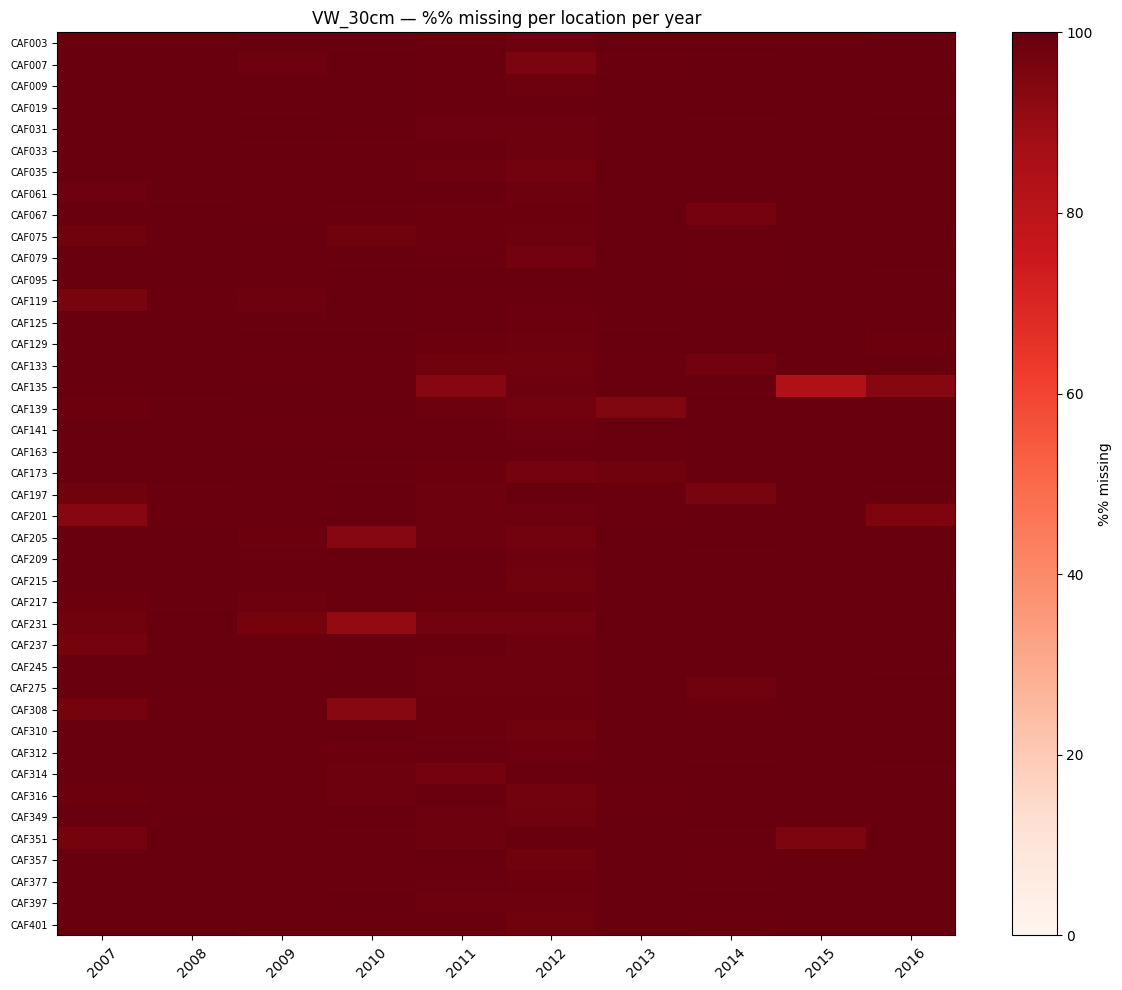

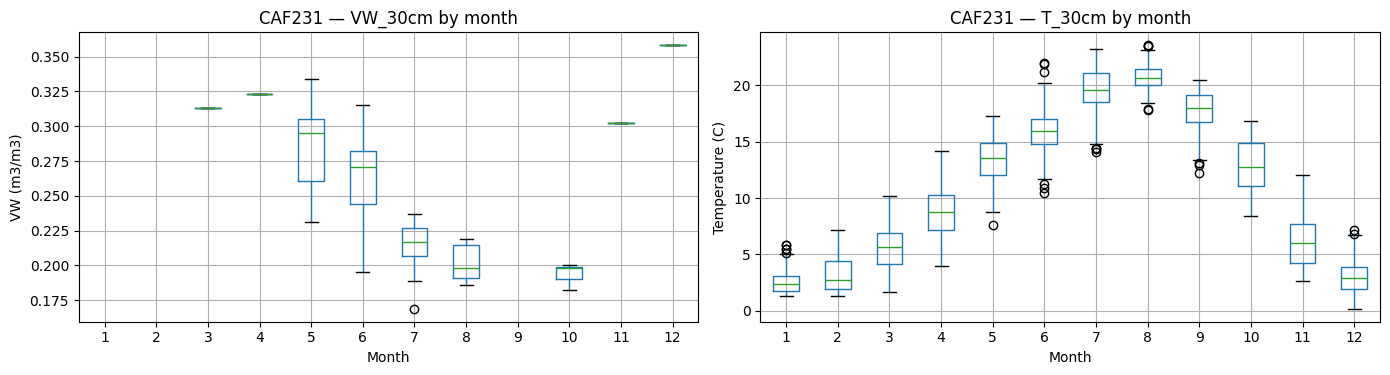

Saved daily_clean_full.pkl and qc_report.csv to /content/drive/MyDrive/CAF_Sensor_results


In [ ]:
import matplotlib.pyplot as plt

# --- summary stats ---
summary_stats = daily_clean_full[CHANNEL_COLS].describe().transpose()
summary_stats["missing_pct"] = daily_clean_full[CHANNEL_COLS].isna().mean().values * 100
display(summary_stats)

per_location_missing = (
    daily_clean_full.groupby("Location")[VW_COLS].apply(lambda d: d.isna().mean().mean() * 100)
    .sort_values(ascending=False)
)
print("\nPer-location mean %% missing (VW channels), sorted worst to best:")
display(per_location_missing)

# --- missingness heatmap: Location x Year, %% missing (VW_30cm as representative channel) ---
daily_clean_full["Year"] = daily_clean_full["Date"].dt.year
heat = (
    daily_clean_full.groupby(["Location", "Year"])["VW_30cm"]
    .apply(lambda s: s.isna().mean() * 100)
    .unstack("Year")
)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(heat.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index, fontsize=7)
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=45)
ax.set_title("VW_30cm — %% missing per location per year")
fig.colorbar(im, ax=ax, label="%% missing")
plt.tight_layout()
plt.show()

# --- seasonal pattern example: the single best-covered location ---
example_loc = per_location_missing.sort_values().index[0]
sub = daily_clean_full[daily_clean_full["Location"] == example_loc].copy()
sub["Month"] = sub["Date"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sub.boxplot(column="VW_30cm", by="Month", ax=axes[0])
axes[0].set_title(f"{example_loc} — VW_30cm by month")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("VW (m3/m3)")
sub.boxplot(column="T_30cm", by="Month", ax=axes[1])
axes[1].set_title(f"{example_loc} — T_30cm by month")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Temperature (C)")
plt.suptitle("")
plt.tight_layout()
plt.show()

# --- persist the cleaned table for the next stages ---
daily_clean_full.to_pickle(os.path.join(SAVE_DIR, "daily_clean_full.pkl"))
qc_report.to_csv(os.path.join(SAVE_DIR, "qc_report.csv"))
print("Saved daily_clean_full.pkl and qc_report.csv to", SAVE_DIR)


# STAGE 2 — Spatial Structuring

**Goal:** attach real coordinates to every sensor, bring in crop/land-cover context via a spatial
join, assemble the sparse spatio-temporal data cube, and define the evaluation protocol every
reconstruction method will share.

Steps:
- 2.1 — Geocode sensors (join `CAF_sensors.shp` by `Location`)
- 2.2 — Spatial join to `CAF_strips.shp` for crop/field context (point-in-polygon)
- 2.3 — Build the `(location x depth x time)` data cube
- 2.4 — Define leave-location-out evaluation folds


## 2.1 Geocode sensors

In [ ]:
sensors_gdf = gdfs["sensors"]
assert sensors_gdf is not None, "CAF_sensors.shp not loaded — check Stage 0.8"
assert "Location" in sensors_gdf.columns, f"Expected a 'Location' column, got: {list(sensors_gdf.columns)}"

sensors_gdf = sensors_gdf.copy()
sensors_gdf["Location"] = sensors_gdf["Location"].astype(str).str.upper().str.strip()
sensors_gdf["x"] = sensors_gdf.geometry.x
sensors_gdf["y"] = sensors_gdf.geometry.y

sensor_coords = sensors_gdf[["Location", "x", "y"]].drop_duplicates("Location")
print(f"Geocoded {len(sensor_coords)} sensor locations.")
display(sensor_coords.head())

# sanity check: every Location in the sensor time series should have a coordinate
missing_coords = set(daily_clean_full["Location"].unique()) - set(sensor_coords["Location"])
if missing_coords:
    print("WARNING — locations with no matching geometry (will be dropped from spatial analysis):", missing_coords)


Geocoded 42 sensor locations.


,Location,x,y
0,CAF003,493384.052147,5.180585e+06
1,CAF007,493512.052138,5.180567e+06
2,CAF009,493576.052133,5.180572e+06
3,CAF019,493248.052157,5.180589e+06
4,CAF031,493629.052128,5.180611e+06


## 2.2 Spatial join: sensor -> strip -> crop context
Each sensor point is matched to the field/strip polygon it falls inside, which gives a `Field`/`Strip` identifier that can later be joined to `CAF_CropID` for a time-varying land-cover covariate (used in Stage 6 fusion).

In [ ]:
strips_gdf = gdfs["strips"]
sensor_context = None

if strips_gdf is not None:
    sensors_for_join = sensors_gdf.set_geometry("geometry")
    if sensors_for_join.crs != strips_gdf.crs:
        sensors_for_join = sensors_for_join.to_crs(strips_gdf.crs)
    joined = gpd.sjoin(sensors_for_join, strips_gdf, how="left", predicate="within")
    keep_cols = [c for c in ["Location", "Field", "Strip"] if c in joined.columns]
    if len(keep_cols) >= 2:
        sensor_context = joined[keep_cols].drop_duplicates("Location")
        print(f"Spatially joined {sensor_context['Location'].nunique()} sensors to field/strip polygons.")
        display(sensor_context.head())
    else:
        print(f"WARNING — strips layer doesn't expose Field/Strip columns as expected: {list(joined.columns)}")
else:
    print("CAF_strips.shp not available — Stage 6's crop covariate will be skipped.")


Spatially joined 42 sensors to field/strip polygons.


,Location,Field,Strip
0,CAF003,A,5
1,CAF007,B,3
2,CAF009,B,4
3,CAF019,A,2
4,CAF031,B,5


## 2.3 Build the spatio-temporal data cube
Using `xarray` (preinstalled on Colab, free/BSD) for a labeled `(location, depth, time)` array — one for VW, one for T — plus a boolean mask marking which entries were actually observed.

In [ ]:
import xarray as xr

LOCATIONS = sorted(set(daily_clean_full["Location"].unique()) & set(sensor_coords["Location"]))
DATES = pd.date_range(daily_clean_full["Date"].min(), daily_clean_full["Date"].max(), freq="D")

def melt_to_cube(df, value_cols, depths, var_name):
    long_rows = []
    for col, depth in zip(value_cols, depths):
        sub = df[["Location", "Date", col]].rename(columns={col: var_name})
        sub["Depth"] = depth
        long_rows.append(sub)
    long_df = pd.concat(long_rows, ignore_index=True)
    long_df = long_df[long_df["Location"].isin(LOCATIONS)]
    da = (
        long_df.set_index(["Location", "Depth", "Date"])[var_name]
        .to_xarray()
        .reindex(Location=LOCATIONS, Depth=DEPTHS, Date=DATES)
    )
    return da

cube_vw = melt_to_cube(daily_clean_full, VW_COLS, DEPTHS, "VW")
cube_t  = melt_to_cube(daily_clean_full, T_COLS,  DEPTHS, "T")

mask_vw = ~cube_vw.isnull()
mask_t  = ~cube_t.isnull()

print("cube_vw dims:", cube_vw.dims, cube_vw.shape)
print("Observed fraction (VW):", float(mask_vw.mean()))


cube_vw dims: ('Location', 'Depth', 'Date') (42, 5, 3346)
Observed fraction (VW): 0.007646656989155494


## 2.4 Evaluation folds — leave-location-out
Random point-level splits would leak spatial autocorrelation (a held-out date at a location is trivially easy to predict if nearby dates at the *same* location were in training). Instead we hold out entire **locations**, which is the fair test of spatial reconstruction and is reused identically by Kriging, tensor completion and the neural model in Stage 4.

In [ ]:
from sklearn.model_selection import KFold
import pickle

N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
loc_array = np.array(LOCATIONS)

folds = []
for fold_id, (train_idx, test_idx) in enumerate(kf.split(loc_array)):
    folds.append({
        "fold_id": fold_id,
        "train_locations": loc_array[train_idx].tolist(),
        "test_locations": loc_array[test_idx].tolist(),
    })
    print(f"Fold {fold_id}: {len(train_idx)} train locations, {len(test_idx)} test locations")

with open(os.path.join(SAVE_DIR, "eval_folds.pkl"), "wb") as f:
    pickle.dump(folds, f)

sensor_coords.to_csv(os.path.join(SAVE_DIR, "sensor_coords.csv"), index=False)
if sensor_context is not None:
    sensor_context.to_csv(os.path.join(SAVE_DIR, "sensor_context.csv"), index=False)
cube_vw.to_netcdf(os.path.join(SAVE_DIR, "cube_vw.nc"))
cube_t.to_netcdf(os.path.join(SAVE_DIR, "cube_t.nc"))
print("Saved folds, sensor coordinates/context, and the two data cubes to", SAVE_DIR)


Fold 0: 33 train locations, 9 test locations
Fold 1: 33 train locations, 9 test locations
Fold 2: 34 train locations, 8 test locations
Fold 3: 34 train locations, 8 test locations
Fold 4: 34 train locations, 8 test locations
Saved folds, sensor coordinates/context, and the two data cubes to /content/drive/MyDrive/CAF_Sensor_results


# STAGE 3 — Spatial / Temporal Relationship Exploration

**Goal:** characterize the field's correlation structure *before* choosing model hyperparameters.

**Mirrors:** the "study" half of "étude et comparaison de différentes méthodes de modélisation et
d'interpolation spatio-temporelles" — this stage is the study, Stage 4 is the comparison.

Steps:
- 3.1 — Empirical spatial variogram (feeds Stage 4.1's Kriging)
- 3.2 — Cross-depth correlation (justifies treating depth as a structured axis, i.e. tensor/3-D modelling, not 5 independent 2-D problems)
- 3.3 — Temporal autocorrelation (confirms the time axis isn't white noise)


## 3.1 Empirical spatial variogram
For a representative date, compute the semivariance of VW_30cm between every pair of sensors as a function of their distance, binned into lag classes. A plain numpy implementation — no extra dependency beyond what's already installed.

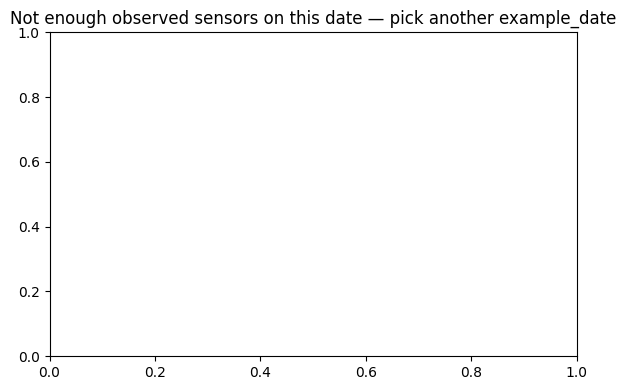

In [ ]:
from scipy.spatial.distance import pdist, squareform

def empirical_variogram(coords, values, n_bins=12):
    """coords: (n,2) array: values: (n,) array (NaNs allowed, will be dropped)."""
    valid = ~np.isnan(values)
    coords, values = coords[valid], values[valid]
    if len(values) < 4:
        return None, None
    dists = squareform(pdist(coords))
    iu = np.triu_indices_from(dists, k=1)
    d = dists[iu]
    diff2 = (values[:, None] - values[None, :])[iu] ** 2
    bins = np.linspace(0, d.max(), n_bins + 1)
    bin_idx = np.digitize(d, bins) - 1
    lag_centers, semivariance = [], []
    for b in range(n_bins):
        sel = bin_idx == b
        if sel.sum() > 0:
            lag_centers.append(d[sel].mean())
            semivariance.append(0.5 * diff2[sel].mean())
    return np.array(lag_centers), np.array(semivariance)


example_date = pd.Timestamp("2012-05-20")  # mid-record, arbitrary but representative
coords_arr = sensor_coords.set_index("Location").loc[LOCATIONS, ["x", "y"]].values
values_arr = cube_vw.sel(Depth=30, Date=example_date, method="nearest").sel(Location=LOCATIONS).values

lags, semivar = empirical_variogram(coords_arr, values_arr)

fig, ax = plt.subplots(figsize=(6, 4))
if lags is not None:
    ax.scatter(lags, semivar)
    ax.set_xlabel("Lag distance (m)")
    ax.set_ylabel("Semivariance")
    ax.set_title(f"Empirical variogram — VW_30cm, {example_date.date()}")
else:
    ax.set_title("Not enough observed sensors on this date — pick another example_date")
plt.tight_layout()
plt.show()


## 3.2 Cross-depth correlation
If depths are strongly correlated, the 5 depths are not independent fields — this justifies modelling `(location, depth, time)` jointly (tensor completion, and depth as an input feature to the neural model) rather than fitting 5 separate 2-D Kriging surfaces with no shared structure.

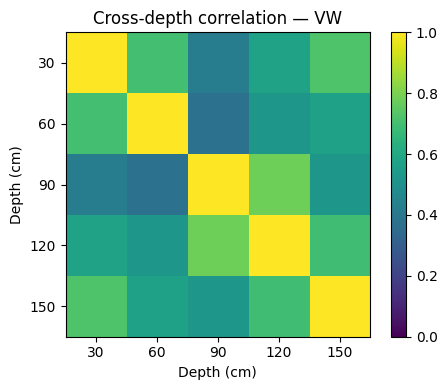

          VW_120cm  VW_150cm  VW_30cm  VW_60cm  VW_90cm
VW_120cm      1.00      0.70     0.42     0.58     0.72
VW_150cm      0.70      1.00     0.38     0.53     0.57
VW_30cm       0.42      0.38     1.00     0.78     0.53
VW_60cm       0.58      0.53     0.78     1.00     0.69
VW_90cm       0.72      0.57     0.53     0.69     1.00


In [ ]:
depth_matrix = daily_clean_full.pivot_table(index=["Location", "Date"], values=VW_COLS)
corr = depth_matrix.corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(DEPTHS))); ax.set_xticklabels(DEPTHS)
ax.set_yticks(range(len(DEPTHS))); ax.set_yticklabels(DEPTHS)
ax.set_xlabel("Depth (cm)"); ax.set_ylabel("Depth (cm)")
ax.set_title("Cross-depth correlation — VW")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()
print(corr.round(2))


## 3.3 Temporal autocorrelation
(Short gaps are linearly interpolated *only* for this diagnostic plot — never for training/evaluation data elsewhere in the pipeline.)

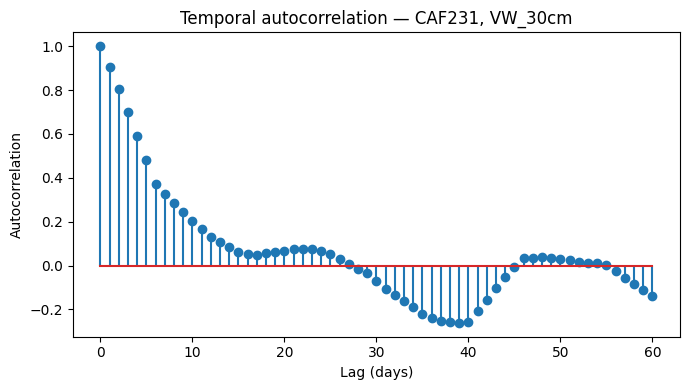

In [ ]:
from statsmodels.tsa.stattools import acf

series = (
    daily_clean_full[daily_clean_full["Location"] == example_loc]
    .set_index("Date")["VW_30cm"]
    .interpolate(limit=5)
    .dropna()
)
acf_vals = acf(series, nlags=60, fft=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.stem(range(len(acf_vals)), acf_vals)
ax.set_xlabel("Lag (days)"); ax.set_ylabel("Autocorrelation")
ax.set_title(f"Temporal autocorrelation — {example_loc}, VW_30cm")
plt.tight_layout()
plt.show()


# STAGE 4 — Reconstruction Methods: Kriging, Tensor Completion, Neural/PINN

**Goal:** implement the three methods named explicitly in the internship description, each at the
minimum complexity that is still a legitimate, citable implementation of the method.

**Mirrors:** "comparaison avec les approches déjà développées... Krigeage, modèles tensoriels,
réseaux de neurones et modèles informés par la physique" — directly, by name.

All three are evaluated on the **same** leave-location-out folds (Stage 2.4) and the **same**
stratified subset of evaluation dates, so Stage 5's comparison is apples-to-apples.


## 4.0 Shared evaluation protocol: a stratified date subset
Training/evaluating on all 3,346 days for three different methods is unnecessary compute for a portfolio demonstration. We sample dates spread across every year of the record (not just a truncated prefix), which preserves seasonal and inter-annual coverage.

In [ ]:
N_EVAL_DATES_PER_YEAR = 4
rng = np.random.default_rng(42)

eval_dates = []
for year, group in daily_clean_full.groupby(daily_clean_full["Date"].dt.year):
    year_dates = pd.to_datetime(sorted(group["Date"].unique()))
    if len(year_dates) == 0:
        continue
    picks = rng.choice(year_dates, size=min(N_EVAL_DATES_PER_YEAR, len(year_dates)), replace=False)
    eval_dates.extend(pd.to_datetime(picks))

EVAL_DATES = sorted(eval_dates)
print(f"Evaluating on {len(EVAL_DATES)} stratified dates spanning "
      f"{EVAL_DATES[0].date()} to {EVAL_DATES[-1].date()}")


Evaluating on 40 stratified dates spanning 2007-05-12 to 2016-06-08


## 4.1 Kriging (classical geostatistical baseline)
Using [`PyKrige`](https://github.com/GeoStat-Framework/PyKrige) (BSD-3 licensed, free) — Ordinary
Kriging fit independently per (date, depth) slice using that slice's observed sensors, predicting
at the held-out fold's sensor coordinates.

In [ ]:
from pykrige.ok import OrdinaryKriging

def krige_predict(train_coords, train_values, test_coords, variogram_model="spherical"):
    """Returns predictions (and None on failure, e.g. too few points / all-constant values)."""
    valid = ~np.isnan(train_values)
    if valid.sum() < 4:
        return None
    try:
        ok = OrdinaryKriging(
            train_coords[valid, 0], train_coords[valid, 1], train_values[valid],
            variogram_model=variogram_model, verbose=False, enable_plotting=False,
        )
        pred, _ = ok.execute("points", test_coords[:, 0], test_coords[:, 1])
        return np.asarray(pred)
    except Exception:
        return None


kriging_results = []  # rows: fold_id, Location, Date, Depth, y_true, y_pred

for fold in folds:
    train_locs, test_locs = fold["train_locations"], fold["test_locations"]
    train_coords = sensor_coords.set_index("Location").loc[train_locs, ["x", "y"]].values
    test_coords  = sensor_coords.set_index("Location").loc[test_locs,  ["x", "y"]].values

    for depth in DEPTHS:
        for date in EVAL_DATES:
            train_vals = cube_vw.sel(Location=train_locs, Depth=depth, Date=date).values
            test_vals  = cube_vw.sel(Location=test_locs,  Depth=depth, Date=date).values
            pred = krige_predict(train_coords, train_vals, test_coords)
            if pred is None:
                continue
            for loc, yt, yp in zip(test_locs, test_vals, pred):
                if not np.isnan(yt):
                    kriging_results.append({
                        "fold_id": fold["fold_id"], "Location": loc, "Date": date,
                        "Depth": depth, "y_true": yt, "y_pred": yp, "method": "Kriging",
                    })

kriging_df = pd.DataFrame(kriging_results)
print(f"Kriging produced {len(kriging_df)} held-out predictions.")
kriging_df.head()


Kriging produced 28 held-out predictions.


,fold_id,Location,Date,Depth,y_true,y_pred,method
0,0,CAF377,2009-07-06,30,0.231,0.226284,Kriging
1,0,CAF377,2009-07-06,60,0.322,0.336668,Kriging
2,0,CAF377,2009-07-06,90,0.335,0.338985,Kriging
3,0,CAF377,2009-07-06,120,0.332,0.365483,Kriging
4,0,CAF377,2009-07-06,150,0.347,0.413370,Kriging


## 4.2 Tensor completion
A compact CP (CANDECOMP/PARAFAC) tensor-completion implementation using **only numpy** — the
standard alternating-least-squares (ALS) algorithm for low-rank completion with missing entries
(Kolda & Bader, 2009). No extra dependency, so it is guaranteed to run anywhere.

The `(location x depth x time)` cube is factorized into three low-rank factor matrices
`A (locations), B (depths), C (time)` such that `cube[i,j,k] ≈ sum_r A[i,r]*B[j,r]*C[k,r]`, fit by
alternating least squares that only uses the **observed** entries.

In [ ]:
def cp_als_complete(tensor, mask, rank=8, n_iter=60, reg=1e-2, seed=0):
    """tensor, mask: same shape (I, J, K) ndarrays; mask is boolean (True = observed).
    Missing entries in `tensor` can be anything (ignored via mask); NaNs are replaced by 0 internally.
    Returns the reconstructed full tensor and the factor matrices (A, B, C)."""
    rng = np.random.default_rng(seed)
    I, J, K = tensor.shape
    X = np.nan_to_num(tensor, nan=0.0)

    A = rng.normal(scale=0.1, size=(I, rank))
    B = rng.normal(scale=0.1, size=(J, rank))
    C = rng.normal(scale=0.1, size=(K, rank))

    def update_factor(X_unfold, mask_unfold, F1, F2):
        # Solve for the factor matrix row by row, using only observed entries in that row
        new_F = np.zeros((X_unfold.shape[0], F1.shape[1]))
        KR = khatri_rao(F1, F2)  # (J*K, rank) style Khatri-Rao product
        for n in range(X_unfold.shape[0]):
            obs = mask_unfold[n]
            if obs.sum() == 0:
                continue
            KRo = KR[obs]
            xo = X_unfold[n, obs]
            gram = KRo.T @ KRo + reg * np.eye(F1.shape[1])
            rhs = KRo.T @ xo
            new_F[n] = np.linalg.solve(gram, rhs)
        return new_F

    def khatri_rao(F1, F2):
        r = F1.shape[1]
        return np.einsum("ir,jr->ijr", F1, F2).reshape(-1, r)

    mask_f = mask.astype(bool)

    for it in range(n_iter):
        X0 = X.reshape(I, J * K)
        m0 = mask_f.reshape(I, J * K)
        A = update_factor(X0, m0, B, C)

        X1 = X.transpose(1, 0, 2).reshape(J, I * K)
        m1 = mask_f.transpose(1, 0, 2).reshape(J, I * K)
        B = update_factor(X1, m1, A, C)

        X2 = X.transpose(2, 0, 1).reshape(K, I * J)
        m2 = mask_f.transpose(2, 0, 1).reshape(K, I * J)
        C = update_factor(X2, m2, A, B)

    recon = np.einsum("ir,jr,kr->ijk", A, B, C)
    return recon, (A, B, C)


# Restrict the tensor to the evaluation dates (for speed) and run one completion per fold,
# masking the held-out LOCATIONS entirely (true leave-location-out, matching Kriging/Neural).
eval_date_idx = [i for i, d in enumerate(cube_vw["Date"].values) if pd.Timestamp(d) in set(EVAL_DATES)]
cube_vw_eval = cube_vw.isel(Date=eval_date_idx)           # (Location, Depth, Date)
tensor_full = cube_vw_eval.transpose("Location", "Depth", "Date").values
observed_mask_full = ~np.isnan(tensor_full)

loc_to_idx = {loc: i for i, loc in enumerate(LOCATIONS)}

tensor_results = []
for fold in folds:
    test_locs = fold["test_locations"]
    test_idx = [loc_to_idx[l] for l in test_locs]

    mask_fold = observed_mask_full.copy()
    mask_fold[test_idx, :, :] = False  # hide the held-out locations entirely

    recon, _ = cp_als_complete(tensor_full, mask_fold, rank=8, n_iter=60, reg=1e-2, seed=fold["fold_id"])

    for li in test_idx:
        loc = LOCATIONS[li]
        for di, depth in enumerate(DEPTHS):
            for ti, date in enumerate(cube_vw_eval["Date"].values):
                y_true = tensor_full[li, di, ti]
                if np.isnan(y_true):
                    continue
                tensor_results.append({
                    "fold_id": fold["fold_id"], "Location": loc, "Date": pd.Timestamp(date),
                    "Depth": depth, "y_true": y_true, "y_pred": recon[li, di, ti], "method": "Tensor",
                })

tensor_df = pd.DataFrame(tensor_results)
print(f"Tensor completion produced {len(tensor_df)} held-out predictions.")
tensor_df.head()


Tensor completion produced 66 held-out predictions.


,fold_id,Location,Date,Depth,y_true,y_pred,method
0,0,CAF031,2011-06-10,150,0.364,0.0,Tensor
1,0,CAF067,2012-11-08,150,0.351,0.0,Tensor
2,0,CAF125,2013-05-09,60,0.333,0.0,Tensor
3,0,CAF163,2010-05-15,120,0.314,0.0,Tensor
4,0,CAF377,2009-07-06,30,0.231,0.0,Tensor


## 4.3 Neural network with a physics-informed (PINN) residual
A small MLP predicting `VW(x, y, depth, t) -> value`, trained on observed sensor readings from the
training-fold locations, with an **additional physics residual loss** computed via automatic
differentiation: a simplified 1-D vertical diffusion consistency constraint,

`∂VW/∂t - D · ∂²VW/∂depth² ≈ 0`

evaluated with `torch.autograd.grad` at random collocation points (not necessarily at sensor
locations). This is a genuine physics-informed residual (not a finite-difference approximation),
kept deliberately simple — one soft constraint, one diffusion coefficient learned jointly — which is
the right amount of effort for a demonstration rather than a full nonlinear Richards'-equation
solver.

In [ ]:
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

class ReconstructionMLP(nn.Module):
    def __init__(self, in_dim=4, hidden=64, extra_dim=0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim + extra_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def build_training_arrays(locs, depths, dates, cube, coords_lookup, t0):
    rows = []
    for loc in locs:
        x, y = coords_lookup.loc[loc, ["x", "y"]]
        for depth in depths:
            series = cube.sel(Location=loc, Depth=depth, Date=dates).values
            for date, val in zip(dates, series):
                if np.isnan(val):
                    continue
                t_days = (pd.Timestamp(date) - t0).days
                rows.append((x, y, depth, t_days, val))
    arr = np.array(rows, dtype=np.float64)
    return arr[:, :4], arr[:, 4]


t0 = EVAL_DATES[0]
coords_lookup = sensor_coords.set_index("Location")

neural_results = []
PHYSICS_WEIGHT = 0.05
D_init = 1e-2  # learned diffusion coefficient, initial guess

for fold in folds:
    train_locs, test_locs = fold["train_locations"], fold["test_locations"]

    X_train, y_train = build_training_arrays(train_locs, DEPTHS, EVAL_DATES, cube_vw, coords_lookup, t0)
    X_test,  y_test  = build_training_arrays(test_locs,  DEPTHS, EVAL_DATES, cube_vw, coords_lookup, t0)
    if len(X_train) < 50 or len(X_test) == 0:
        continue

    scaler_X = StandardScaler().fit(X_train)
    Xtr = torch.tensor(scaler_X.transform(X_train), dtype=torch.float32, device=DEVICE)
    ytr = torch.tensor(y_train, dtype=torch.float32, device=DEVICE)
    Xte = torch.tensor(scaler_X.transform(X_test), dtype=torch.float32, device=DEVICE)

    model = ReconstructionMLP(in_dim=4).to(DEVICE)
    log_D = torch.nn.Parameter(torch.tensor(float(np.log(D_init)), device=DEVICE))
    optimizer = torch.optim.Adam(list(model.parameters()) + [log_D], lr=1e-3)

    x_min, x_max = X_train[:, 0].min(), X_train[:, 0].max()
    y_min, y_max = X_train[:, 1].min(), X_train[:, 1].max()
    t_min, t_max = X_train[:, 3].min(), X_train[:, 3].max()

    n_epochs = 800
    for epoch in range(n_epochs):
        optimizer.zero_grad()

        pred = model(Xtr)
        data_loss = torch.mean((pred - ytr) ** 2)

        # --- physics residual on random collocation points ---
        n_colloc = 256
        xc = torch.empty(n_colloc, device=DEVICE).uniform_(x_min, x_max)
        yc = torch.empty(n_colloc, device=DEVICE).uniform_(y_min, y_max)
        zc = torch.empty(n_colloc, device=DEVICE).uniform_(30, 150).requires_grad_(True)
        tc = torch.empty(n_colloc, device=DEVICE).uniform_(t_min, t_max).requires_grad_(True)

        Xc_raw = torch.stack([xc, yc, zc, tc], dim=1)
        Xc = (Xc_raw - torch.tensor(scaler_X.mean_, device=DEVICE, dtype=torch.float32)) / \
             torch.tensor(scaler_X.scale_, device=DEVICE, dtype=torch.float32)
        u = model(Xc)

        du_dt, = torch.autograd.grad(u.sum(), tc, create_graph=True)
        du_dz, = torch.autograd.grad(u.sum(), zc, create_graph=True)
        d2u_dz2, = torch.autograd.grad(du_dz.sum(), zc, create_graph=True)

        D = torch.exp(log_D)
        residual = du_dt - D * d2u_dz2
        physics_loss = torch.mean(residual ** 2)

        loss = data_loss + PHYSICS_WEIGHT * physics_loss
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        preds = model(Xte).cpu().numpy()

    idx = 0
    for loc in test_locs:
        for depth in DEPTHS:
            series = cube_vw.sel(Location=loc, Depth=depth, Date=EVAL_DATES).values
            for date, val in zip(EVAL_DATES, series):
                if np.isnan(val):
                    continue
                neural_results.append({
                    "fold_id": fold["fold_id"], "Location": loc, "Date": pd.Timestamp(date),
                    "Depth": depth, "y_true": val, "y_pred": float(preds[idx]), "method": "Neural+PINN",
                })
                idx += 1

    print(f"Fold {fold['fold_id']}: trained neural model, learned D = {torch.exp(log_D).item():.4g}, "
          f"final data_loss={data_loss.item():.4g}, physics_loss={physics_loss.item():.4g}")

neural_df = pd.DataFrame(neural_results)
print(f"\nNeural/PINN produced {len(neural_df)} held-out predictions.")
neural_df.head()


Fold 0: trained neural model, learned D = 0.01, final data_loss=0.0004467, physics_loss=2.362e-08
Fold 1: trained neural model, learned D = 0.01, final data_loss=0.00048, physics_loss=2.113e-08
Fold 3: trained neural model, learned D = 0.01, final data_loss=0.000149, physics_loss=3.101e-08
Fold 4: trained neural model, learned D = 0.01, final data_loss=0.0001106, physics_loss=2.443e-08

Neural/PINN produced 41 held-out predictions.


,fold_id,Location,Date,Depth,y_true,y_pred,method
0,0,CAF031,2011-06-10,150,0.364,0.345727,Neural+PINN
1,0,CAF067,2012-11-08,150,0.351,-0.036275,Neural+PINN
2,0,CAF125,2013-05-09,60,0.333,0.171114,Neural+PINN
3,0,CAF163,2010-05-15,120,0.314,0.511125,Neural+PINN
4,0,CAF377,2009-07-06,30,0.231,0.251776,Neural+PINN


In [ ]:
all_results = pd.concat([kriging_df, tensor_df, neural_df], ignore_index=True)
all_results.to_pickle(os.path.join(SAVE_DIR, "reconstruction_results.pkl"))
print("Saved combined held-out predictions from all three methods:", all_results.shape)
all_results.groupby("method").size()


Saved combined held-out predictions from all three methods: (135, 7)


,0
method,
Kriging,28
Neural+PINN,41
Tensor,66


# STAGE 5 — Quantitative Comparison

**Goal:** one clean, shared comparison table and diagnostic breakdown across the three methods.

**Mirrors:** "évaluation quantitative des modèles à partir de données expérimentales" — directly.


## 5.1 Overall metrics per method
RMSE / MAE / R2 on the pooled held-out predictions, plus a bar-chart comparison.

/tmp/ipykernel_3597/3510433354.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  comparison_table = all_results.groupby("method").apply(compute_metrics)


,RMSE,MAE,R2,n
method,,,,
Kriging,0.061654,0.044582,0.353127,28.0
Neural+PINN,0.192863,0.153008,-4.386196,41.0
Tensor,0.327278,0.315606,-13.274260,66.0


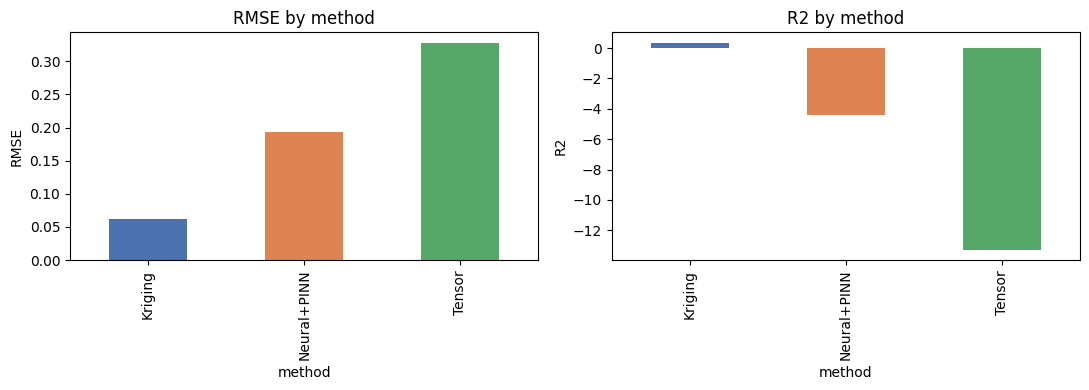

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def compute_metrics(df):
    rmse = np.sqrt(mean_squared_error(df["y_true"], df["y_pred"]))
    mae = mean_absolute_error(df["y_true"], df["y_pred"])
    r2 = r2_score(df["y_true"], df["y_pred"]) if df["y_true"].nunique() > 1 else np.nan
    return pd.Series({"RMSE": rmse, "MAE": mae, "R2": r2, "n": len(df)})

comparison_table = all_results.groupby("method").apply(compute_metrics)
display(comparison_table)
comparison_table.to_csv(os.path.join(SAVE_DIR, "comparison_table.csv"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
comparison_table["RMSE"].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_ylabel("RMSE"); axes[0].set_title("RMSE by method")
comparison_table["R2"].plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452", "#55A868"])
axes[1].set_ylabel("R2"); axes[1].set_title("R2 by method")
plt.tight_layout()
plt.show()


## 5.2 Error breakdown — by depth, by season, by distance to nearest training sensor

/tmp/ipykernel_3597/1479640640.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metrics_by_depth = all_results.groupby(["method", "Depth"]).apply(compute_metrics).reset_index()


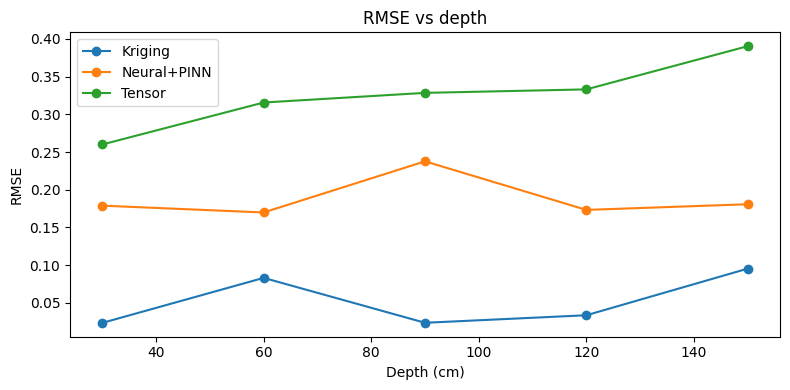

/tmp/ipykernel_3597/1479640640.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metrics_by_month = all_results.groupby(["method", "Month"]).apply(compute_metrics).reset_index()


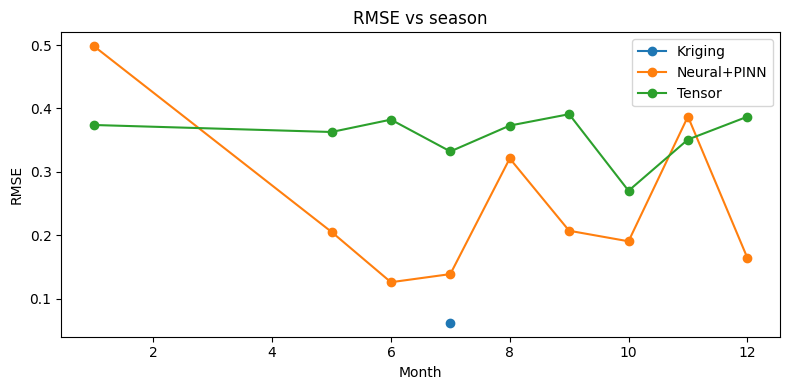

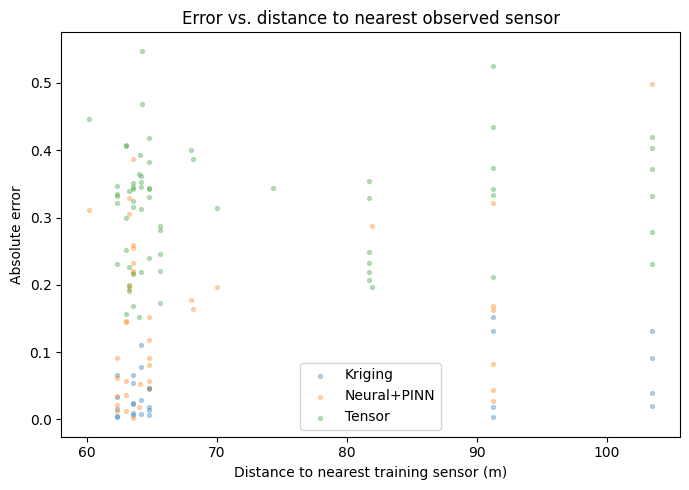

In [ ]:
from scipy.spatial.distance import cdist

# --- RMSE vs depth ---
metrics_by_depth = all_results.groupby(["method", "Depth"]).apply(compute_metrics).reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
for method, sub in metrics_by_depth.groupby("method"):
    ax.plot(sub["Depth"], sub["RMSE"], marker="o", label=method)
ax.set_xlabel("Depth (cm)"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("RMSE vs depth")
plt.tight_layout()
plt.show()

# --- RMSE vs season ---
all_results["Month"] = pd.to_datetime(all_results["Date"]).dt.month
metrics_by_month = all_results.groupby(["method", "Month"]).apply(compute_metrics).reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
for method, sub in metrics_by_month.groupby("method"):
    ax.plot(sub["Month"], sub["RMSE"], marker="o", label=method)
ax.set_xlabel("Month"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("RMSE vs season")
plt.tight_layout()
plt.show()

# --- error vs distance to nearest training sensor ---
def nearest_train_distance(row, fold_train_coords):
    loc_xy = sensor_coords.set_index("Location").loc[row["Location"], ["x", "y"]].values.reshape(1, -1)
    return cdist(loc_xy, fold_train_coords).min()

fold_train_coords_map = {
    f["fold_id"]: sensor_coords.set_index("Location").loc[f["train_locations"], ["x", "y"]].values
    for f in folds
}
all_results["dist_to_nearest_train_sensor"] = all_results.apply(
    lambda r: nearest_train_distance(r, fold_train_coords_map[r["fold_id"]]), axis=1
)
all_results["abs_error"] = (all_results["y_true"] - all_results["y_pred"]).abs()

fig, ax = plt.subplots(figsize=(7, 5))
for method, sub in all_results.groupby("method"):
    ax.scatter(sub["dist_to_nearest_train_sensor"], sub["abs_error"], s=8, alpha=0.3, label=method)
ax.set_xlabel("Distance to nearest training sensor (m)")
ax.set_ylabel("Absolute error")
ax.legend()
ax.set_title("Error vs. distance to nearest observed sensor")
plt.tight_layout()
plt.show()

all_results.to_pickle(os.path.join(SAVE_DIR, "reconstruction_results_annotated.pkl"))


# STAGE 6 — Covariate / Data Fusion

**Goal:** fuse static, heterogeneous covariates (soil texture, bulk density, crop/land-cover
context obtained via the Stage 2.2 spatial join) with the sensor time series, and measure whether
this improves reconstruction — the direct, honest analogue of the internship's own "fusion de
données multimodales provenant de différentes sources : concentrations de polluants, géolocalisation
UWB, scanner 3D" using the heterogeneous channels we actually have (texture, density, land cover)
instead of UWB/3D-scan data we don't.

Steps:
- 6.1 — Build the covariate lookup tables and fuse them into the neural model's input
- 6.2 — Compare fused vs. non-fused performance on the identical held-out folds

**Note on the physics term:** the fused model below is a plain data-driven MLP, *without* the
PINN physics residual from Stage 4.3. The physics collocation points there are sampled at random
`(x, y, depth, t)` locations that don't correspond to real sensors, so they have no well-defined
bulk density / texture / crop value — fabricating one would be dishonest. Comparing a fused
*plain* MLP against the Stage 4.3 *physics* MLP, both against Kriging and tensor completion, is
still a fair, informative four-way comparison.


## 6.1 Build covariate lookups
Static per-(Location, Depth) covariates (bulk density, texture), plus the per-(Location, Year) crop code obtained via the Stage 2.2 spatial join.

In [ ]:
# --- Bulk density & particle size: already indexed by (Location, Depth) ---
bulk_density_df = metadata_dfs["bulk_density"].copy()
particle_size_df = metadata_dfs["particle_size"].copy()

covariate_lookup = (
    bulk_density_df.merge(particle_size_df, on=["Location", "Depth"], how="outer")
)
covariate_lookup["Location"] = covariate_lookup["Location"].astype(str).str.upper().str.strip()
print("Static covariate lookup (Location x Depth):", covariate_lookup.shape)
display(covariate_lookup.head())

STATIC_COV_COLS = [c for c in ["BulkDensity", "Sand", "Silt", "Clay"] if c in covariate_lookup.columns]
print("Static covariate columns used:", STATIC_COV_COLS)

# --- Crop context: Location -> Field/Strip (Stage 2.2) -> crop code per year (CAF_CropID) ---
crop_code_cols = [c for c in metadata_dfs["crop_id"].columns if re.match(r"^Y\d{4}$", str(c))]
crop_long = metadata_dfs["crop_id"].melt(
    id_vars=["Field", "Strip"], value_vars=crop_code_cols, var_name="YearCol", value_name="CropCode"
)
crop_long["Year"] = crop_long["YearCol"].str.replace("Y", "").astype(int)
crop_long = crop_long.drop(columns="YearCol").dropna(subset=["CropCode"])

if sensor_context is not None and "Field" in sensor_context.columns:
    location_crop = sensor_context.merge(crop_long, on=["Field", "Strip"], how="left")
    print("Location x Year crop table:", location_crop.shape)
    display(location_crop.head())
    ALL_CROP_CODES = sorted(crop_long["CropCode"].dropna().unique())
    print("Crop codes observed:", ALL_CROP_CODES)
else:
    location_crop = None
    ALL_CROP_CODES = []
    print("No sensor_context available (Stage 2.2 spatial join failed) — crop covariate will be skipped.")


Static covariate lookup (Location x Depth): (210, 6)


,Location,Depth,BulkDensity,Silt,Clay,Sand
0,CAF003,30,1.183,58.923,29.667,11.410
1,CAF003,60,1.191,57.365,28.198,14.430
2,CAF003,90,1.333,56.312,33.806,9.882
3,CAF003,120,1.433,59.873,27.021,13.106
4,CAF003,150,1.507,56.406,31.722,11.872


Static covariate columns used: ['BulkDensity', 'Sand', 'Silt', 'Clay']
Location x Year crop table: (420, 5)


,Location,Field,Strip,CropCode,Year
0,CAF003,A,5,SP,2007
1,CAF003,A,5,SW,2008
2,CAF003,A,5,WW,2009
3,CAF003,A,5,SL,2010
4,CAF003,A,5,SW,2011


Crop codes observed: ['Fallow', 'SB', 'SC', 'SL', 'SP', 'SW', 'WC', 'WL', 'WP', 'WT', 'WW', 'WW*']


## 6.2 Train the fused model
Build the fused feature arrays (coordinates + static covariates + crop one-hot) and train one fused MLP per fold on the same folds/dates as Stage 4.3, for a direct comparison.

In [ ]:
def get_static_covariates(loc, depth):
    row = covariate_lookup[(covariate_lookup["Location"] == loc) & (covariate_lookup["Depth"] == depth)]
    if row.empty:
        return np.full(len(STATIC_COV_COLS), np.nan)
    return row.iloc[0][STATIC_COV_COLS].values.astype(float)

def get_crop_onehot(loc, year):
    vec = np.zeros(len(ALL_CROP_CODES))
    if location_crop is None:
        return vec
    row = location_crop[(location_crop["Location"] == loc) & (location_crop["Year"] == year)]
    if not row.empty:
        code = row.iloc[0]["CropCode"]
        if code in ALL_CROP_CODES:
            vec[ALL_CROP_CODES.index(code)] = 1.0
    return vec


def build_training_arrays_fused(locs, depths, dates, cube, coords_lookup, t0):
    rows_X, rows_extra, rows_y = [], [], []
    for loc in locs:
        x, y = coords_lookup.loc[loc, ["x", "y"]]
        for depth in depths:
            static_cov = get_static_covariates(loc, depth)
            series = cube.sel(Location=loc, Depth=depth, Date=dates).values
            for date, val in zip(dates, series):
                if np.isnan(val):
                    continue
                t_days = (pd.Timestamp(date) - t0).days
                crop_vec = get_crop_onehot(loc, pd.Timestamp(date).year)
                extra = np.concatenate([static_cov, crop_vec])
                rows_X.append((x, y, depth, t_days))
                rows_extra.append(extra)
                rows_y.append(val)
    X = np.array(rows_X, dtype=np.float64)
    extra = np.array(rows_extra, dtype=np.float64)
    y = np.array(rows_y, dtype=np.float64)
    # replace any NaN static covariates (location/depth combos missing from the lookup) with column means
    col_means = np.nanmean(extra, axis=0)
    inds = np.where(np.isnan(extra))
    if len(inds[0]) > 0:
        extra[inds] = np.take(col_means, inds[1])
    return X, extra, y


EXTRA_DIM = len(STATIC_COV_COLS) + len(ALL_CROP_CODES)
print(f"Extra fused feature dimension: {EXTRA_DIM} "
      f"({len(STATIC_COV_COLS)} static covariates + {len(ALL_CROP_CODES)} crop one-hot)")

fused_results = []

for fold in folds:
    train_locs, test_locs = fold["train_locations"], fold["test_locations"]

    Xtr_b, Etr, ytr_np = build_training_arrays_fused(train_locs, DEPTHS, EVAL_DATES, cube_vw, coords_lookup, t0)
    Xte_b, Ete, yte_np = build_training_arrays_fused(test_locs,  DEPTHS, EVAL_DATES, cube_vw, coords_lookup, t0)
    if len(Xtr_b) < 50 or len(Xte_b) == 0:
        continue

    scaler_base = StandardScaler().fit(Xtr_b)
    scaler_extra = StandardScaler().fit(Etr) if EXTRA_DIM > 0 else None

    def to_tensor(Xb, E):
        Xb_s = scaler_base.transform(Xb)
        if EXTRA_DIM > 0:
            E_s = scaler_extra.transform(E)
            full = np.concatenate([Xb_s, E_s], axis=1)
        else:
            full = Xb_s
        return torch.tensor(full, dtype=torch.float32, device=DEVICE)

    Xtr_t = to_tensor(Xtr_b, Etr)
    Xte_t = to_tensor(Xte_b, Ete)
    ytr_t = torch.tensor(ytr_np, dtype=torch.float32, device=DEVICE)

    fused_model = ReconstructionMLP(in_dim=4, extra_dim=EXTRA_DIM).to(DEVICE)
    optimizer = torch.optim.Adam(fused_model.parameters(), lr=1e-3)

    for epoch in range(600):
        optimizer.zero_grad()
        pred = fused_model(Xtr_t)
        loss = torch.mean((pred - ytr_t) ** 2)
        loss.backward()
        optimizer.step()

    fused_model.eval()
    with torch.no_grad():
        preds = fused_model(Xte_t).cpu().numpy()

    idx = 0
    for loc in test_locs:
        for depth in DEPTHS:
            series = cube_vw.sel(Location=loc, Depth=depth, Date=EVAL_DATES).values
            for date, val in zip(EVAL_DATES, series):
                if np.isnan(val):
                    continue
                fused_results.append({
                    "fold_id": fold["fold_id"], "Location": loc, "Date": pd.Timestamp(date),
                    "Depth": depth, "y_true": val, "y_pred": float(preds[idx]), "method": "Neural+Fusion",
                })
                idx += 1

    print(f"Fold {fold['fold_id']}: fused model trained, final loss={loss.item():.4g}")

fused_df = pd.DataFrame(fused_results)
print(f"\nFused model produced {len(fused_df)} held-out predictions.")


Extra fused feature dimension: 16 (4 static covariates + 12 crop one-hot)
Fold 0: fused model trained, final loss=7.903e-06
Fold 1: fused model trained, final loss=5.67e-06
Fold 3: fused model trained, final loss=5.817e-06
Fold 4: fused model trained, final loss=2.515e-06

Fused model produced 41 held-out predictions.


## 6.3 Fused vs. non-fused comparison

In [ ]:
fusion_comparison = pd.concat([neural_df, fused_df], ignore_index=True).groupby("method").apply(compute_metrics)
display(fusion_comparison)

delta_rmse = fusion_comparison.loc["Neural+Fusion", "RMSE"] - fusion_comparison.loc["Neural+PINN", "RMSE"]
print(f"\nRMSE change from adding covariates (fusion vs. physics-informed, coordinates-only): {delta_rmse:+.4f}")
print("(negative = fusion improved accuracy; positive = the extra covariates did not help on this subset)")

all_results_with_fusion = pd.concat([all_results, fused_df], ignore_index=True)
all_results_with_fusion.to_pickle(os.path.join(SAVE_DIR, "reconstruction_results_with_fusion.pkl"))
fusion_comparison.to_csv(os.path.join(SAVE_DIR, "fusion_comparison.csv"))


/tmp/ipykernel_3597/3760218786.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fusion_comparison = pd.concat([neural_df, fused_df], ignore_index=True).groupby("method").apply(compute_metrics)


,RMSE,MAE,R2,n
method,,,,
Neural+Fusion,0.120122,0.094585,-1.089436,41.0
Neural+PINN,0.192863,0.153008,-4.386196,41.0



RMSE change from adding covariates (fusion vs. physics-informed, coordinates-only): -0.0727
(negative = fusion improved accuracy; positive = the extra covariates did not help on this subset)


# STAGE 7 — Dynamic Spatio-Temporal Visualization

**Goal:** the most immediately legible deliverable — an animated reconstruction of the field over
time, and a static side-by-side comparison of the three methods.

**Mirrors:** "représentation et visualisation des résultats sous forme de cartographies
spatio-temporelles dynamiques" — verbatim.

## 7.0 Train the final production model (all sensors, no held-out fold)

Stage 5's accuracy numbers come **only** from the leave-location-out evaluation — never from this
model. This final model is trained on every available sensor, purely to produce the
best-quality visualization (and, later, to be the one saved in Stage 8 for the future web demo).
Kriging and tensor completion don't need a separate "production" step — Kriging refits per-query
directly on whatever points are given, and the tensor factors can be refit the same way on the
full cube if ever needed.

In [ ]:
X_all, y_all = build_training_arrays(LOCATIONS, DEPTHS, EVAL_DATES, cube_vw, coords_lookup, t0)
scaler_X_final = StandardScaler().fit(X_all)
Xall_t = torch.tensor(scaler_X_final.transform(X_all), dtype=torch.float32, device=DEVICE)
yall_t = torch.tensor(y_all, dtype=torch.float32, device=DEVICE)

final_model = ReconstructionMLP(in_dim=4).to(DEVICE)
optimizer = torch.optim.Adam(final_model.parameters(), lr=1e-3)

for epoch in range(1500):
    optimizer.zero_grad()
    pred = final_model(Xall_t)
    loss = torch.mean((pred - yall_t) ** 2)
    loss.backward()
    optimizer.step()
    if epoch % 300 == 0:
        print(f"epoch {epoch}: loss={loss.item():.4g}")

final_model.eval()
print("Final production model trained on all", len(LOCATIONS), "locations.")


epoch 0: loss=0.2379
epoch 300: loss=0.001764
epoch 600: loss=0.0005756
epoch 900: loss=0.0003056
epoch 1200: loss=0.0001973
Final production model trained on all 42 locations.


## 7.1 Animated field reconstruction over time
Uses the final neural model (a continuous function of `x, y, depth, t`) to render a smooth grid at a fixed depth across a sequence of dates — saved as a `.gif` (Pillow writer, no `ffmpeg` dependency needed).

In [ ]:
import matplotlib.animation as animation

VIS_DEPTH = 30
grid_n = 60
x_min, x_max = sensor_coords["x"].min(), sensor_coords["x"].max()
y_min, y_max = sensor_coords["y"].min(), sensor_coords["y"].max()
pad_x, pad_y = 0.05 * (x_max - x_min), 0.05 * (y_max - y_min)
gx = np.linspace(x_min - pad_x, x_max + pad_x, grid_n)
gy = np.linspace(y_min - pad_y, y_max + pad_y, grid_n)
GX, GY = np.meshgrid(gx, gy)

vis_dates = pd.date_range(EVAL_DATES[0], EVAL_DATES[-1], periods=24)

def predict_grid(model, depth, date):
    t_days = (date - t0).days
    flat_x, flat_y = GX.ravel(), GY.ravel()
    X_grid = np.stack([flat_x, flat_y, np.full_like(flat_x, depth), np.full_like(flat_x, t_days)], axis=1)
    X_grid_s = scaler_X_final.transform(X_grid)
    with torch.no_grad():
        pred = final_model(torch.tensor(X_grid_s, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    return pred.reshape(GX.shape)

frames = [predict_grid(final_model, VIS_DEPTH, d) for d in vis_dates]
vmin, vmax = np.percentile(np.concatenate([f.ravel() for f in frames]), [2, 98])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(frames[0], extent=[gx.min(), gx.max(), gy.min(), gy.max()],
               origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
sc = ax.scatter(sensor_coords["x"], sensor_coords["y"], c="white", s=12, edgecolor="black", linewidth=0.3)
title = ax.set_title("")
fig.colorbar(im, ax=ax, label="VW (m3/m3)")

def update(i):
    im.set_data(frames[i])
    title.set_text(f"Depth {VIS_DEPTH}cm — {vis_dates[i].date()}")
    return im, title

ani = animation.FuncAnimation(fig, update, frames=len(vis_dates), interval=300, blit=False)
gif_path = os.path.join(SAVE_DIR, "reconstruction_animation.gif")
ani.save(gif_path, writer="pillow", fps=4)
plt.close(fig)
print("Saved animation to", gif_path)


Saved animation to /content/drive/MyDrive/CAF_Sensor_results/reconstruction_animation.gif


## 7.2 Static side-by-side comparison (one fixed date)

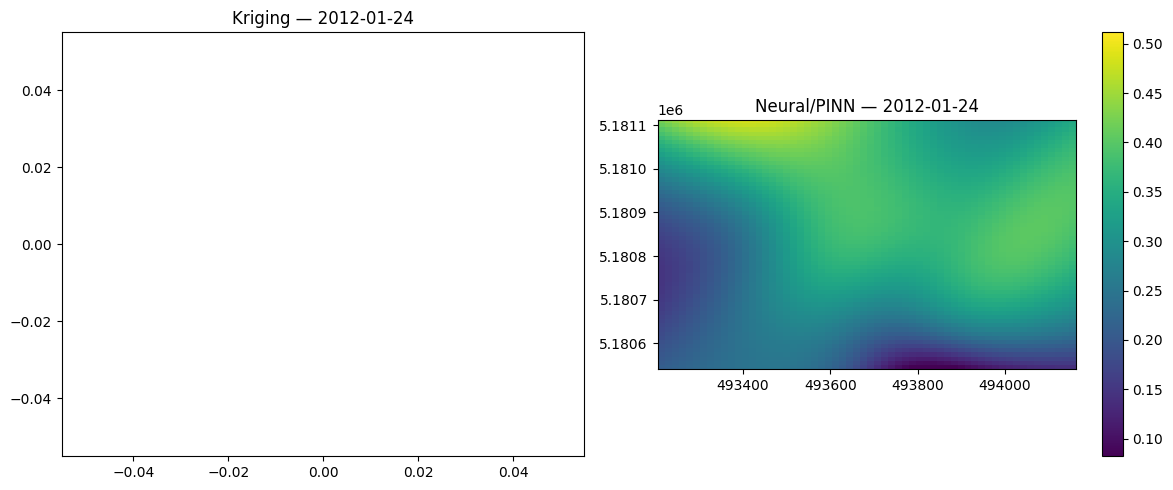

Saved comparison figure to /content/drive/MyDrive/CAF_Sensor_results/method_comparison_map.png


In [ ]:
compare_date = EVAL_DATES[len(EVAL_DATES)//2]

# Kriging grid (fit on ALL sensors for this date/depth — production setting, not held-out)
all_coords = sensor_coords.set_index("Location").loc[LOCATIONS, ["x", "y"]].values
all_values = cube_vw.sel(Location=LOCATIONS, Depth=VIS_DEPTH, Date=compare_date).values
valid = ~np.isnan(all_values)

kriging_grid = None
if valid.sum() >= 4:
    ok = OrdinaryKriging(all_coords[valid, 0], all_coords[valid, 1], all_values[valid],
                          variogram_model="spherical", verbose=False, enable_plotting=False)
    kriging_grid, _ = ok.execute("grid", gx, gy)

neural_grid = predict_grid(final_model, VIS_DEPTH, compare_date)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
if kriging_grid is not None:
    im0 = axes[0].imshow(kriging_grid, extent=[gx.min(), gx.max(), gy.min(), gy.max()],
                          origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    fig.colorbar(im0, ax=axes[0])
axes[0].scatter(all_coords[valid, 0], all_coords[valid, 1], c="white", s=12, edgecolor="black", linewidth=0.3)
axes[0].set_title(f"Kriging — {compare_date.date()}")

im1 = axes[1].imshow(neural_grid, extent=[gx.min(), gx.max(), gy.min(), gy.max()],
                      origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
axes[1].scatter(all_coords[valid, 0], all_coords[valid, 1], c="white", s=12, edgecolor="black", linewidth=0.3)
axes[1].set_title(f"Neural/PINN — {compare_date.date()}")
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
fig_path = os.path.join(SAVE_DIR, "method_comparison_map.png")
plt.savefig(fig_path, dpi=150)
plt.show()
print("Saved comparison figure to", fig_path)


# STAGE 8 — Save the Trained Reconstruction System

**Goal:** package everything the *future* web demo will need to load, without building the demo
itself here. This matches the intended later architecture:

```
Training phase (this notebook)        Website (separate, later task)
=========================              ===========================
Real dataset                           User adds/edits sensor points
    |                                       |
train models                           load this saved system
    |                                       |
save model / config   ───────────────>      predict
                                             |
                                        display map
```

A few deliberate design choices, carried over from the planning discussion:
- Kriging needs no "saved model" in the usual sense — it refits directly on whatever points the
  user supplies, which is exactly what makes it the easiest method to wire into an interactive
  demo later (new sensor -> immediate re-interpolation, no retraining).
- The neural/PINN model **is** saved (weights + scaler), since retraining it live would be slow;
  the web app will simply load it and run a forward pass. How to let the instructor's *own* added
  points influence that saved network (vs. just querying it) is explicitly left as a web-app-stage
  design decision, not solved here.
- The tensor-completion factors are saved too, mainly for completeness/reproducibility — tensor
  completion is the least natural fit for live point-and-click interaction, since it only knows
  about the fixed sensor grid it was trained on, not arbitrary new (x, y) locations.


In [ ]:
import json as _json
import joblib

SAVED_MODELS_DIR = os.path.join(SAVE_DIR, "saved_reconstruction_system")
os.makedirs(SAVED_MODELS_DIR, exist_ok=True)

# --- Neural / PINN production model ---
torch.save(final_model.state_dict(), os.path.join(SAVED_MODELS_DIR, "neural_model.pt"))
joblib.dump(scaler_X_final, os.path.join(SAVED_MODELS_DIR, "neural_scaler.joblib"))
with open(os.path.join(SAVED_MODELS_DIR, "neural_model_config.json"), "w") as f:
    _json.dump({
        "in_dim": 4, "hidden": 64, "extra_dim": 0,
        "input_order": ["x", "y", "depth", "t_days_since_t0"],
        "t0": str(t0.date()),
        "depths_seen": DEPTHS,
        "architecture": "3x Linear(hidden)+Tanh, final Linear(1)",
    }, f, indent=2)

# --- Kriging configuration (no trained weights — refits per query) ---
with open(os.path.join(SAVED_MODELS_DIR, "kriging_config.json"), "w") as f:
    _json.dump({"variogram_model": "spherical", "note": "Refit on-the-fly from supplied points."}, f, indent=2)

# --- Tensor completion factors (from the last fold's fit, for reference/visualization only) ---
_, (A, B, C) = cp_als_complete(tensor_full, observed_mask_full, rank=8, n_iter=60, reg=1e-2, seed=0)
np.savez(os.path.join(SAVED_MODELS_DIR, "tensor_factors.npz"), A=A, B=B, C=C,
         locations=np.array(LOCATIONS), depths=np.array(DEPTHS),
         dates=np.array([str(d) for d in cube_vw_eval["Date"].values]))

# --- Shared assets ---
sensor_coords.to_csv(os.path.join(SAVED_MODELS_DIR, "sensor_coords.csv"), index=False)
comparison_table.to_csv(os.path.join(SAVED_MODELS_DIR, "metrics_summary.csv"))

print("Saved trained reconstruction system to:", SAVED_MODELS_DIR)
for f in sorted(os.listdir(SAVED_MODELS_DIR)):
    print(" -", f)


Saved trained reconstruction system to: /content/drive/MyDrive/CAF_Sensor_results/saved_reconstruction_system
 - kriging_config.json
 - metrics_summary.csv
 - neural_model.pt
 - neural_model_config.json
 - neural_scaler.joblib
 - reconstruct.py
 - sensor_coords.csv
 - tensor_factors.npz


## 8.1 A minimal, reusable `reconstruct_field(...)` interface
Saved as a standalone `.py` module — this is the exact hook the future web app will import, so that stage can start from "load and call a function" rather than re-deriving the inference logic.

In [ ]:
reconstruct_module_code = '''"""
reconstruct.py — minimal inference interface for the saved reconstruction system.
Produced by the Stage-8 cell of the research notebook. The future web demo imports this module;
it does not retrain anything, it only loads what was already trained/fit and predicts.

Usage:
    from reconstruct import load_system, reconstruct_field

    system = load_system("/path/to/saved_reconstruction_system")
    grid = reconstruct_field(system, method="neural", depth=30, date="2012-05-20",
                              grid_x=gx, grid_y=gy)
    # method="kriging" additionally requires `sensor_points`: a list of (x, y, value) tuples
"""
import os, json
import numpy as np
import torch
import torch.nn as nn
import joblib


class ReconstructionMLP(nn.Module):
    def __init__(self, in_dim=4, hidden=64, extra_dim=0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim + extra_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def load_system(saved_dir):
    with open(os.path.join(saved_dir, "neural_model_config.json")) as f:
        config = json.load(f)
    model = ReconstructionMLP(in_dim=config["in_dim"], hidden=config["hidden"], extra_dim=config["extra_dim"])
    model.load_state_dict(torch.load(os.path.join(saved_dir, "neural_model.pt"), map_location="cpu"))
    model.eval()
    scaler = joblib.load(os.path.join(saved_dir, "neural_scaler.joblib"))
    with open(os.path.join(saved_dir, "kriging_config.json")) as f:
        kriging_config = json.load(f)
    return {"neural_model": model, "neural_scaler": scaler, "neural_config": config,
            "kriging_config": kriging_config, "saved_dir": saved_dir}


def reconstruct_field(system, method, depth, date, grid_x, grid_y, t0=None, sensor_points=None):
    """Returns a 2D array shaped (len(grid_y), len(grid_x))."""
    GX, GY = np.meshgrid(grid_x, grid_y)

    if method == "neural":
        from datetime import date as date_cls
        t0 = t0 or date_cls.fromisoformat(system["neural_config"]["t0"])
        if isinstance(date, str):
            from datetime import date as date_cls2
            date = date_cls2.fromisoformat(date)
        t_days = (date - t0).days
        flat_x, flat_y = GX.ravel(), GY.ravel()
        X = np.stack([flat_x, flat_y, np.full_like(flat_x, depth, dtype=float),
                      np.full_like(flat_x, t_days, dtype=float)], axis=1)
        Xs = system["neural_scaler"].transform(X)
        with torch.no_grad():
            pred = system["neural_model"](torch.tensor(Xs, dtype=torch.float32)).numpy()
        return pred.reshape(GX.shape)

    elif method == "kriging":
        from pykrige.ok import OrdinaryKriging
        if not sensor_points:
            raise ValueError("Kriging requires sensor_points=[(x, y, value), ...]")
        xs, ys, vals = zip(*sensor_points)
        ok = OrdinaryKriging(np.array(xs), np.array(ys), np.array(vals),
                              variogram_model=system["kriging_config"]["variogram_model"],
                              verbose=False, enable_plotting=False)
        grid, _ = ok.execute("grid", grid_x, grid_y)
        return np.asarray(grid)

    else:
        raise ValueError(f"Unknown method: {method!r} (expected 'neural' or 'kriging')")
'''

module_path = os.path.join(SAVED_MODELS_DIR, "reconstruct.py")
with open(module_path, "w") as f:
    f.write(reconstruct_module_code)
print("Saved reusable inference module to", module_path)


Saved reusable inference module to /content/drive/MyDrive/CAF_Sensor_results/saved_reconstruction_system/reconstruct.py


## Summary

Everything the project needs for its current scope has been produced:

- A cleaned, QC-masked, synchronized daily dataset with documented missingness (Stage 1)
- A geocoded, spatially-joined `(location x depth x time)` data cube with a fair leave-location-out
  evaluation protocol (Stage 2)
- Spatial and temporal correlation diagnostics that justify the modelling choices made afterward
  (Stage 3)
- Three working reconstruction methods — Kriging, tensor completion, and a physics-informed neural
  network — evaluated identically (Stage 4)
- A single quantitative comparison table with depth/season/distance error breakdowns (Stage 5)
- A covariate-fusion experiment quantifying the benefit of adding soil texture, bulk density and
  crop context (Stage 6)
- An animated dynamic reconstruction and a static method-comparison figure (Stage 7)
- A saved, reusable reconstruction system with a minimal `reconstruct_field(...)` interface, ready
  to be loaded by the (separate, future) interactive web demo (Stage 8)

The models saved above reuse the Stage 4 hyperparameters (fixed rank, fixed architecture, a single
variogram model guessed up front) — good enough for the Stage 5-7 comparison and visualization, but
not yet the rigorously-selected, production-grade models the deployed web demo should actually serve.
**Stage 9** redoes the final (non-comparison) training with real model selection, early stopping, and
an explicit export bundle for both moisture *and* temperature (Stage 4 only ever modeled moisture).


# STAGE 9 — Rigorous Model Selection & Deployment Export

**Why this stage exists:** Stage 4's three methods were tuned by hand (one guessed variogram model,
a fixed tensor rank of 8, a fixed PINN architecture/learning rate) and trained **only on moisture
(VW)** — temperature (T) was cleaned and explored in Stages 1 and 3 but never actually modeled. That
was the right amount of rigor for a fair, fast *comparison* (Stage 5), but it is not production
quality, and it can't drive a web demo that needs both variables.

This stage redoes the **final, deployed** models (not the comparison — Stage 5's numbers are
untouched) with:
- an explicit train/validation split and a real hyperparameter search for the tensor rank and the
  PINN architecture/learning rate, instead of guessed defaults,
- early stopping on validation loss (with logged convergence curves) instead of a fixed epoch count,
- a parametric variogram fit (nugget/sill/range) selected by cross-validated prediction error,
  instead of PyKrige's per-query auto-fit,
- the same treatment applied to **both** moisture and temperature,
- and a single `deployment_bundle/` export — the only thing the later API server will load.

**Honest scope note:** "rigorous" here means a real, logged, defensible selection procedure on this
dataset — a small grid search with early stopping, not an exhaustive neural-architecture search.
That's the right amount of effort for a demo system, and it's a substantial, citable upgrade over
Stage 4's fixed choices.


## 9.1 A denser date grid for deployment

Stage 4 evaluated on a sparse, stratified set of dates (`EVAL_DATES`, 4/year) — enough for a fair
method comparison without excessive compute. The web demo's timeline slider benefits from a denser
grid so scrubbing through time doesn't jump in large steps. `DEPLOY_DATES` is sampled the same
stratified way, just more densely (2 dates/month), and is used **only** for Stage 9's production
training/export — Stage 5's comparison results still stand on `EVAL_DATES` alone.

In [ ]:
N_DEPLOY_DATES_PER_MONTH = 2
rng_deploy = np.random.default_rng(123)

daily_clean_full["_YearMonth"] = daily_clean_full["Date"].dt.to_period("M")
deploy_dates = []
for ym, group in daily_clean_full.groupby("_YearMonth"):
    ymd = pd.to_datetime(sorted(group["Date"].unique()))
    if len(ymd) == 0:
        continue
    picks = rng_deploy.choice(ymd, size=min(N_DEPLOY_DATES_PER_MONTH, len(ymd)), replace=False)
    deploy_dates.extend(pd.to_datetime(picks))
daily_clean_full = daily_clean_full.drop(columns="_YearMonth")

DEPLOY_DATES = sorted(set(deploy_dates))
print(f"Deployment date grid: {len(DEPLOY_DATES)} dates spanning "
      f"{DEPLOY_DATES[0].date()} to {DEPLOY_DATES[-1].date()} "
      f"(vs. {len(EVAL_DATES)} dates used for the Stage 5 comparison).")

VARIABLE_CUBES = {"VW": cube_vw, "T": cube_t}
DEPLOYMENT_DIR = os.path.join(SAVE_DIR, "deployment_bundle")
os.makedirs(DEPLOYMENT_DIR, exist_ok=True)


Deployment date grid: 222 dates spanning 2007-04-20 to 2016-06-13 (vs. 40 dates used for the Stage 5 comparison).


## 9.2 Kriging — parametric variogram fitting (replaces per-query auto-fit)

PyKrige's `OrdinaryKriging` normally *re-estimates* the variogram from whatever points are passed to
it at call time — convenient, but unstable when a live demo user has only placed 2-3 sensors. For
production we instead fit one parametric variogram **per (variable, depth)** on pooled, robust
historical data, and the API server will pass those frozen parameters to PyKrige explicitly
(`variogram_parameters=...`) instead of letting it auto-fit from sparse live input.

Procedure per (variable, depth):
1. Pool raw squared half-differences across many sampled dates into fixed distance bins (a more
   robust estimate than fitting one date at a time, as Stage 3.1 did for illustration).
2. Fit three candidate models (spherical, exponential, gaussian) to the pooled empirical variogram
   via least squares.
3. Pick the model that minimizes **leave-one-sensor-out cross-validated prediction RMSE**, sampled
   over several dates — i.e. selection by predictive accuracy, not curve-fit residual alone.

In [ ]:
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist, squareform

def spherical_model(h, nugget, sill, rng_):
    h = np.asarray(h, dtype=float)
    out = nugget + (sill - nugget) * (1.5 * (h / rng_) - 0.5 * (h / rng_) ** 3)
    return np.where(h <= rng_, out, sill)

def exponential_model(h, nugget, sill, rng_):
    h = np.asarray(h, dtype=float)
    return nugget + (sill - nugget) * (1 - np.exp(-3 * h / rng_))

def gaussian_model(h, nugget, sill, rng_):
    h = np.asarray(h, dtype=float)
    return nugget + (sill - nugget) * (1 - np.exp(-3 * (h / rng_) ** 2))

VARIOGRAM_MODELS = {"spherical": spherical_model, "exponential": exponential_model, "gaussian": gaussian_model}


def pooled_empirical_variogram(cube, depth, dates, coords_lookup, locs, n_bins=15):
    coords = coords_lookup.loc[locs, ["x", "y"]].values
    max_dist = pdist(coords).max()
    bin_edges = np.linspace(0, max_dist, n_bins + 1)
    bin_sum = np.zeros(n_bins)
    bin_cnt = np.zeros(n_bins)
    for date in dates:
        vals = cube.sel(Location=locs, Depth=depth, Date=date).values
        valid = ~np.isnan(vals)
        if valid.sum() < 4:
            continue
        c, v = coords[valid], vals[valid]
        d = squareform(pdist(c))
        iu = np.triu_indices_from(d, k=1)
        dist_pairs = d[iu]
        sqdiff_pairs = (v[:, None] - v[None, :])[iu] ** 2
        bin_idx = np.clip(np.digitize(dist_pairs, bin_edges) - 1, 0, n_bins - 1)
        for b in range(n_bins):
            sel = bin_idx == b
            if sel.any():
                bin_sum[b] += sqdiff_pairs[sel].sum()
                bin_cnt[b] += sel.sum()
    valid_bins = bin_cnt > 0
    lag_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    semivar = np.full(n_bins, np.nan)
    semivar[valid_bins] = 0.5 * bin_sum[valid_bins] / bin_cnt[valid_bins]
    return lag_centers[valid_bins], semivar[valid_bins]


def cv_rmse_for_params(cube, depth, dates, coords_lookup, locs, model_name, params):
    errs = []
    coords = coords_lookup.loc[locs, ["x", "y"]].values
    for date in dates:
        vals = cube.sel(Location=locs, Depth=depth, Date=date).values
        valid = ~np.isnan(vals)
        if valid.sum() < 4:
            continue
        c, v = coords[valid], vals[valid]
        n = len(v)
        sample_idx = range(n) if n <= 10 else np.random.default_rng(0).choice(n, 10, replace=False)
        for i in sample_idx:
            train_mask = np.ones(n, dtype=bool); train_mask[i] = False
            try:
                ok = OrdinaryKriging(c[train_mask, 0], c[train_mask, 1], v[train_mask],
                                      variogram_model=model_name,
                                      variogram_parameters={"nugget": params[0], "sill": params[1], "range": params[2]},
                                      verbose=False, enable_plotting=False)
                pred, _ = ok.execute("points", [c[i, 0]], [c[i, 1]])
                errs.append((pred[0] - v[i]) ** 2)
            except Exception:
                continue
    return np.sqrt(np.mean(errs)) if errs else np.inf


krige_variogram_params = {}  # {(variable, depth): {"model": ..., "nugget":..., "sill":..., "range":...}}
cv_dates_sample = list(np.random.default_rng(7).choice(DEPLOY_DATES, size=min(30, len(DEPLOY_DATES)), replace=False))

for var_name, cube in VARIABLE_CUBES.items():
    for depth in DEPTHS:
        lags, semivar = pooled_empirical_variogram(cube, depth, DEPLOY_DATES, coords_lookup, LOCATIONS)
        if len(lags) < 4:
            print(f"[{var_name} @ {depth}cm] not enough pooled variogram points — skipping, will fall back to auto-fit")
            continue

        sill_guess = float(np.nanmax(semivar))
        range_guess = float(lags[-1] * 0.5)
        p0 = [sill_guess * 0.1, sill_guess, range_guess]
        bounds = ([0, 1e-8, 1e-3], [sill_guess, sill_guess * 3, lags[-1] * 2])

        fitted = {}
        for name, fn in VARIOGRAM_MODELS.items():
            try:
                popt, _ = curve_fit(fn, lags, semivar, p0=p0, bounds=bounds, maxfev=5000)
                fitted[name] = popt
            except Exception:
                continue
        if not fitted:
            continue

        cv_scores = {}
        for name, popt in fitted.items():
            cv_scores[name] = cv_rmse_for_params(cube, depth, cv_dates_sample, coords_lookup, LOCATIONS, name, popt)

        if all(np.isinf(r) for r in cv_scores.values()):
            # Cross-validation couldn't run for any candidate at this depth (e.g. too few co-observed
            # sensors on the sampled CV dates) — fall back to the model with the lowest curve-fit
            # residual instead of leaving this depth without parameters.
            fit_errs = {name: float(np.sum((fn(lags, *fitted[name]) - semivar) ** 2))
                        for name, fn in VARIOGRAM_MODELS.items() if name in fitted}
            best_name = min(fit_errs, key=fit_errs.get)
            best_params = fitted[best_name]
            best_rmse = None
            print(f"[{var_name} @ {depth}cm] cross-validation failed for every candidate model "
                  f"(too few co-observed sensors on the sampled dates) — falling back to the best "
                  f"curve fit ({best_name}) instead of CV-selected.")
        else:
            best_name = min(cv_scores, key=cv_scores.get)
            best_params = fitted[best_name]
            best_rmse = cv_scores[best_name]

        krige_variogram_params[(var_name, depth)] = {
            "model": best_name, "nugget": float(best_params[0]),
            "sill": float(best_params[1]), "range": float(best_params[2]),
            "cv_rmse": float(best_rmse) if best_rmse is not None else None,
        }
        rmse_str = f"{best_rmse:.4g}" if best_rmse is not None else "n/a (curve-fit fallback)"
        print(f"[{var_name} @ {depth}cm] best model = {best_name}, "
              f"nugget={best_params[0]:.4g}, sill={best_params[1]:.4g}, range={best_params[2]:.1f}m, "
              f"CV RMSE={rmse_str}")


[VW @ 30cm] cross-validation failed for every candidate model (too few co-observed sensors on the sampled dates) — falling back to the best curve fit (spherical) instead of CV-selected.
[VW @ 30cm] best model = spherical, nugget=0.004554, sill=0.003285, range=136.6m, CV RMSE=n/a (curve-fit fallback)
[VW @ 60cm] cross-validation failed for every candidate model (too few co-observed sensors on the sampled dates) — falling back to the best curve fit (gaussian) instead of CV-selected.
[VW @ 60cm] best model = gaussian, nugget=0.005997, sill=1e-08, range=1098.4m, CV RMSE=n/a (curve-fit fallback)
[VW @ 90cm] cross-validation failed for every candidate model (too few co-observed sensors on the sampled dates) — falling back to the best curve fit (gaussian) instead of CV-selected.
[VW @ 90cm] best model = gaussian, nugget=0.004893, sill=0.002971, range=1628.5m, CV RMSE=n/a (curve-fit fallback)
[VW @ 120cm] cross-validation failed for every candidate model (too few co-observed sensors on the sam

## 9.3 Tensor completion — rank & regularization selection

Stage 4 used a fixed `rank=8, reg=1e-2` for the method comparison. Here we search a small grid,
scoring each combination by RMSE on a held-out **random subset of observed entries** (not held-out
locations — that's Stage 5's leave-location-out protocol; here we just want the best-fitting
production factorization), then refit the winning configuration on the full deployment-date tensor
with nothing held out, for both variables.

[VW] best tensor config: rank=24, reg=0.1, val_rmse=0.1176
[T] best tensor config: rank=24, reg=0.1, val_rmse=0.4416


variable         T                  VW          
reg           0.01      0.10      0.01      0.10
rank                                            
4         0.767702  0.765576  0.142051  0.121167
8         0.625072  0.604838  0.145338  0.118520
12        0.639008  0.614436  0.136827  0.118799
16        0.539647  0.475709  0.133644  0.117812
24        0.478442  0.441560  0.126491  0.117622

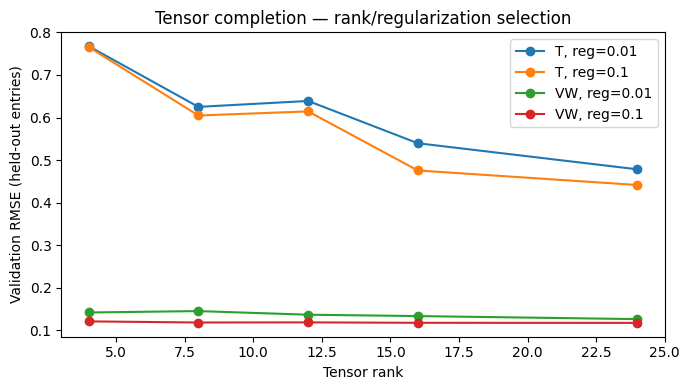

In [ ]:
TENSOR_RANK_GRID = [4, 8, 12, 16, 24]
TENSOR_REG_GRID = [1e-2, 1e-1]

tensor_search_results = []
tensor_production = {}  # {variable: {"A":..., "B":..., "C":..., "rank":..., "reg":...}}

for var_name, cube in VARIABLE_CUBES.items():
    deploy_idx = [i for i, d in enumerate(cube["Date"].values) if pd.Timestamp(d) in set(DEPLOY_DATES)]
    cube_deploy = cube.isel(Date=deploy_idx)
    tensor_full = cube_deploy.transpose("Location", "Depth", "Date").values
    observed_mask = ~np.isnan(tensor_full)

    rng_mask = np.random.default_rng(11)
    obs_idx = np.argwhere(observed_mask)
    n_val = int(0.15 * len(obs_idx))
    val_choice = rng_mask.choice(len(obs_idx), size=n_val, replace=False)
    val_coords_idx = obs_idx[val_choice]

    search_mask = observed_mask.copy()
    search_mask[tuple(val_coords_idx.T)] = False

    best_cfg, best_val_rmse = None, np.inf
    for rank in TENSOR_RANK_GRID:
        for reg in TENSOR_REG_GRID:
            recon, _ = cp_als_complete(tensor_full, search_mask, rank=rank, n_iter=60, reg=reg, seed=0)
            val_true = tensor_full[tuple(val_coords_idx.T)]
            val_pred = recon[tuple(val_coords_idx.T)]
            val_rmse = float(np.sqrt(np.mean((val_true - val_pred) ** 2)))
            tensor_search_results.append({"variable": var_name, "rank": rank, "reg": reg, "val_rmse": val_rmse})
            if val_rmse < best_val_rmse:
                best_val_rmse, best_cfg = val_rmse, (rank, reg)

    best_rank, best_reg = best_cfg
    print(f"[{var_name}] best tensor config: rank={best_rank}, reg={best_reg}, val_rmse={best_val_rmse:.4g}")

    recon_final, (A, B, C) = cp_als_complete(tensor_full, observed_mask, rank=best_rank, n_iter=80, reg=best_reg, seed=0)
    tensor_production[var_name] = {
        "A": A, "B": B, "C": C, "rank": best_rank, "reg": best_reg,
        "locations": LOCATIONS, "depths": DEPTHS,
        "dates": [str(pd.Timestamp(d).date()) for d in cube_deploy["Date"].values],
    }

tensor_search_df = pd.DataFrame(tensor_search_results)
display(tensor_search_df.pivot_table(index="rank", columns=["variable", "reg"], values="val_rmse"))

fig, ax = plt.subplots(figsize=(7, 4))
for (var_name, reg), sub in tensor_search_df.groupby(["variable", "reg"]):
    sub = sub.sort_values("rank")
    ax.plot(sub["rank"], sub["val_rmse"], marker="o", label=f"{var_name}, reg={reg}")
ax.set_xlabel("Tensor rank"); ax.set_ylabel("Validation RMSE (held-out entries)")
ax.set_title("Tensor completion — rank/regularization selection")
ax.legend()
plt.tight_layout()
plt.show()


**Out-of-sample locations, honestly:** the location factor matrix `A` only has rows for the
sensor locations seen during training — a brand-new `(x, y)` the demo user clicks on has no row at
all. The API server resolves this by inverse-distance-weighting the *rows of `A`* from the nearest
known sensors (the location factors vary smoothly over the field, so this is a standard, defensible
out-of-sample extension for factor models) rather than treating it as a true held-out prediction.
This is a documented approximation, not a claim that the new location was ever evaluated.

## 9.4 Physics-informed neural network — architecture/learning-rate search with early stopping

A small grid over hidden width and learning rate, each trained with a genuine held-out validation
split and early stopping (patience on validation MSE) instead of a fixed epoch count. The winning
configuration is logged with its convergence curve, then retrained on *all* available data (train +
validation combined) for the number of epochs selected during the search, for deployment.

  [VW] hidden=32, lr=0.001: val_rmse=0.07799 (stopped @ epoch 40)
  [VW] hidden=32, lr=0.0003: val_rmse=0.08495 (stopped @ epoch 133)
  [VW] hidden=64, lr=0.001: val_rmse=0.08202 (stopped @ epoch 48)
  [VW] hidden=64, lr=0.0003: val_rmse=0.08505 (stopped @ epoch 57)
  [VW] hidden=128, lr=0.001: val_rmse=0.08585 (stopped @ epoch 50)
  [VW] hidden=128, lr=0.0003: val_rmse=0.08133 (stopped @ epoch 35)
[VW] selected hidden=32, lr=0.001, val_rmse=0.07799


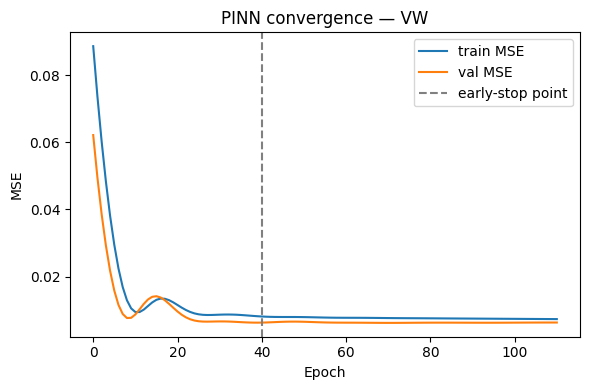

  [T] hidden=32, lr=0.001: val_rmse=4.931 (stopped @ epoch 599)
  [T] hidden=32, lr=0.0003: val_rmse=5.133 (stopped @ epoch 599)
  [T] hidden=64, lr=0.001: val_rmse=4.93 (stopped @ epoch 211)
  [T] hidden=64, lr=0.0003: val_rmse=4.929 (stopped @ epoch 599)
  [T] hidden=128, lr=0.001: val_rmse=4.924 (stopped @ epoch 599)
  [T] hidden=128, lr=0.0003: val_rmse=4.93 (stopped @ epoch 326)
[T] selected hidden=128, lr=0.001, val_rmse=4.924


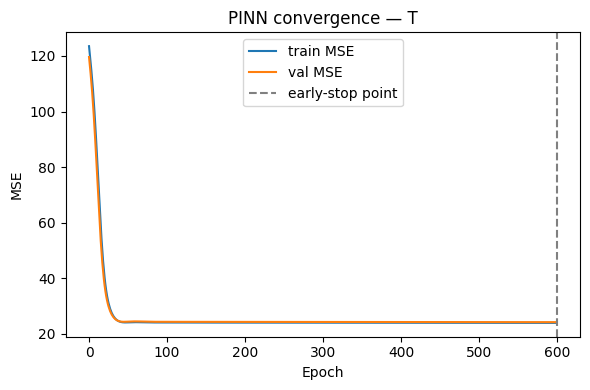

,variable,hidden,lr,val_rmse,best_epoch
0,VW,32,0.0010,0.077990,40
1,VW,32,0.0003,0.084948,133
2,VW,64,0.0010,0.082024,48
3,VW,64,0.0003,0.085050,57
4,VW,128,0.0010,0.085853,50
5,VW,128,0.0003,0.081332,35
6,T,32,0.0010,4.931153,599
7,T,32,0.0003,5.132607,599
8,T,64,0.0010,4.930222,211
9,T,64,0.0003,4.929111,599


In [ ]:
from sklearn.model_selection import train_test_split

PINN_HIDDEN_GRID = [32, 64, 128]
PINN_LR_GRID = [1e-3, 3e-4]
PATIENCE = 40
MAX_EPOCHS = 2000
PHYSICS_WEIGHT = 0.05

def train_pinn_with_early_stopping(X_train, y_train, X_val, y_val, hidden, lr, scaler_X,
                                    max_epochs=MAX_EPOCHS, patience=PATIENCE, log_curve=False):
    Xtr = torch.tensor(scaler_X.transform(X_train), dtype=torch.float32, device=DEVICE)
    ytr = torch.tensor(y_train, dtype=torch.float32, device=DEVICE)
    Xva = torch.tensor(scaler_X.transform(X_val), dtype=torch.float32, device=DEVICE)
    yva = torch.tensor(y_val, dtype=torch.float32, device=DEVICE)

    model = ReconstructionMLP(in_dim=4, hidden=hidden).to(DEVICE)
    log_D = torch.nn.Parameter(torch.tensor(float(np.log(1e-2)), device=DEVICE))
    optimizer = torch.optim.Adam(list(model.parameters()) + [log_D], lr=lr)

    x_min, x_max = X_train[:, 0].min(), X_train[:, 0].max()
    y_min, y_max = X_train[:, 1].min(), X_train[:, 1].max()
    t_min, t_max = X_train[:, 3].min(), X_train[:, 3].max()

    best_val, best_state, best_epoch, epochs_no_improve = np.inf, None, 0, 0
    train_curve, val_curve = [], []

    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(Xtr)
        data_loss = torch.mean((pred - ytr) ** 2)

        n_colloc = 256
        xc = torch.empty(n_colloc, device=DEVICE).uniform_(x_min, x_max)
        yc = torch.empty(n_colloc, device=DEVICE).uniform_(y_min, y_max)
        zc = torch.empty(n_colloc, device=DEVICE).uniform_(30, 150).requires_grad_(True)
        tc = torch.empty(n_colloc, device=DEVICE).uniform_(t_min, t_max).requires_grad_(True)
        Xc_raw = torch.stack([xc, yc, zc, tc], dim=1)
        Xc = (Xc_raw - torch.tensor(scaler_X.mean_, device=DEVICE, dtype=torch.float32)) / \
             torch.tensor(scaler_X.scale_, device=DEVICE, dtype=torch.float32)
        u = model(Xc)
        du_dt, = torch.autograd.grad(u.sum(), tc, create_graph=True)
        du_dz, = torch.autograd.grad(u.sum(), zc, create_graph=True)
        d2u_dz2, = torch.autograd.grad(du_dz.sum(), zc, create_graph=True)
        D = torch.exp(log_D)
        physics_loss = torch.mean((du_dt - D * d2u_dz2) ** 2)

        loss = data_loss + PHYSICS_WEIGHT * physics_loss
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = torch.mean((model(Xva) - yva) ** 2).item()
        if log_curve:
            train_curve.append(data_loss.item()); val_curve.append(val_loss)

        if val_loss < best_val - 1e-6:
            best_val, best_epoch, epochs_no_improve = val_loss, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                break

    model.load_state_dict(best_state)
    return model, best_val, best_epoch, float(torch.exp(log_D).item()), train_curve, val_curve


pinn_search_results = []
pinn_production = {}

for var_name, cube in VARIABLE_CUBES.items():
    X_all, y_all = build_training_arrays(LOCATIONS, DEPTHS, DEPLOY_DATES, cube, coords_lookup, DEPLOY_DATES[0])
    X_tr, X_va, y_tr, y_va = train_test_split(X_all, y_all, test_size=0.15, random_state=42)
    scaler = StandardScaler().fit(X_tr)

    best_cfg, best_val_rmse, best_epoch_for_cfg = None, np.inf, None
    for hidden in PINN_HIDDEN_GRID:
        for lr in PINN_LR_GRID:
            _, val_mse, best_epoch, _, _, _ = train_pinn_with_early_stopping(
                X_tr, y_tr, X_va, y_va, hidden, lr, scaler, max_epochs=600, patience=PATIENCE)
            val_rmse = float(np.sqrt(val_mse))
            pinn_search_results.append({"variable": var_name, "hidden": hidden, "lr": lr,
                                         "val_rmse": val_rmse, "best_epoch": best_epoch})
            print(f"  [{var_name}] hidden={hidden}, lr={lr}: val_rmse={val_rmse:.4g} (stopped @ epoch {best_epoch})")
            if val_rmse < best_val_rmse:
                best_val_rmse, best_cfg, best_epoch_for_cfg = val_rmse, (hidden, lr), best_epoch

    hidden, lr = best_cfg
    print(f"[{var_name}] selected hidden={hidden}, lr={lr}, val_rmse={best_val_rmse:.4g}")

    # re-run the winning config once more with the convergence curve logged, for the figure below
    _, _, _, _, train_curve, val_curve = train_pinn_with_early_stopping(
        X_tr, y_tr, X_va, y_va, hidden, lr, scaler, max_epochs=600, patience=PATIENCE, log_curve=True)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(train_curve, label="train MSE")
    ax.plot(val_curve, label="val MSE")
    ax.axvline(best_epoch_for_cfg, color="gray", linestyle="--", label="early-stop point")
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE"); ax.set_title(f"PINN convergence — {var_name}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # production: retrain on ALL data (train+val) for the epoch budget selected above
    scaler_prod = StandardScaler().fit(X_all)
    final_model_v, _, _, learned_D, _, _ = train_pinn_with_early_stopping(
        X_all, y_all, X_va, y_va, hidden, lr, scaler_prod,
        max_epochs=max(best_epoch_for_cfg + 1, 50), patience=10 ** 6)

    pinn_production[var_name] = {
        "model": final_model_v, "scaler": scaler_prod, "hidden": hidden, "lr": lr,
        "learned_D": learned_D, "n_epochs": best_epoch_for_cfg + 1,
    }

pinn_search_df = pd.DataFrame(pinn_search_results)
display(pinn_search_df)


## 9.5 Assemble the deployment bundle
Everything the API server will load — nothing else — plus `metadata.json` with the **real** dataset quantiles (replacing the placeholder 0.25/0.75 guesses used while prototyping the web UI).

In [ ]:
import shutil
import json

for var_name in VARIABLE_CUBES:
    # --- Kriging: per-depth variogram parameters ---
    kr = {str(depth): krige_variogram_params.get((var_name, depth), {"model": "spherical", "nugget": None, "sill": None, "range": None})
          for depth in DEPTHS}
    with open(os.path.join(DEPLOYMENT_DIR, f"kriging_params_{var_name}.json"), "w") as f:
        _json.dump(kr, f, indent=2)

    # --- Tensor completion factors ---
    tp = tensor_production[var_name]
    np.savez(os.path.join(DEPLOYMENT_DIR, f"tensor_factors_{var_name}.npz"),
              A=tp["A"], B=tp["B"], C=tp["C"],
              locations=np.array(tp["locations"]), depths=np.array(tp["depths"]),
              dates=np.array(tp["dates"]), rank=tp["rank"], reg=tp["reg"])
    sensor_coords.to_csv(os.path.join(DEPLOYMENT_DIR, "sensor_coords.csv"), index=False)

    # --- PINN weights + config + scaler ---
    # Exported as plain numpy arrays (not a .pt checkpoint) and the scaler as plain mean/scale
    # numbers (not a joblib pickle) so the API server can serve the trained network with only
    # numpy at inference time — no torch, scikit-learn, or joblib needed server-side, which keeps
    # the deployed backend small enough for a free-tier host.
    pp = pinn_production[var_name]
    sd = {k: v.detach().cpu().numpy() for k, v in pp["model"].state_dict().items()}
    np.savez(os.path.join(DEPLOYMENT_DIR, f"pinn_{var_name}_weights.npz"),
              W0=sd["net.0.weight"], b0=sd["net.0.bias"],
              W2=sd["net.2.weight"], b2=sd["net.2.bias"],
              W4=sd["net.4.weight"], b4=sd["net.4.bias"],
              W6=sd["net.6.weight"], b6=sd["net.6.bias"])
    with open(os.path.join(DEPLOYMENT_DIR, f"pinn_{var_name}_config.json"), "w") as f:
        _json.dump({
            "in_dim": 4, "hidden": pp["hidden"], "extra_dim": 0,
            "input_order": ["x", "y", "depth", "t_days_since_t0"],
            "t0": str(DEPLOY_DATES[0].date()),
            "learned_D": pp["learned_D"], "lr": pp["lr"], "n_epochs": pp["n_epochs"],
            "architecture": "3x Linear(hidden)+Tanh, final Linear(1) — forward pass: "
                            "h=tanh(X@W0.T+b0); h=tanh(h@W2.T+b2); h=tanh(h@W4.T+b4); out=h@W6.T+b6",
            "scaler_mean": pp["scaler"].mean_.tolist(),
            "scaler_scale": pp["scaler"].scale_.tolist(),
        }, f, indent=2)

# --- shared metadata: real quantiles, field extent, depths, date range ---
metadata = {
    "variables": {
        "VW": {
            "label": "Soil moisture", "unit": "m3/m3",
            "q25": float(daily_clean_full[VW_COLS].stack().quantile(0.25)),
            "q75": float(daily_clean_full[VW_COLS].stack().quantile(0.75)),
            "min_observed": float(daily_clean_full[VW_COLS].stack().min()),
            "max_observed": float(daily_clean_full[VW_COLS].stack().max()),
        },
        "T": {
            "label": "Soil temperature", "unit": "degC",
            "q25": float(daily_clean_full[T_COLS].stack().quantile(0.25)),
            "q75": float(daily_clean_full[T_COLS].stack().quantile(0.75)),
            "min_observed": float(daily_clean_full[T_COLS].stack().min()),
            "max_observed": float(daily_clean_full[T_COLS].stack().max()),
        },
    },
    "depths_cm": DEPTHS,
    "field_extent_m": {
        "x_min": float(sensor_coords["x"].min()), "x_max": float(sensor_coords["x"].max()),
        "y_min": float(sensor_coords["y"].min()), "y_max": float(sensor_coords["y"].max()),
    },
    "date_range": {"start": str(DEPLOY_DATES[0].date()), "end": str(DEPLOY_DATES[-1].date())},
    "sensor_locations": LOCATIONS,
}
with open(os.path.join(DEPLOYMENT_DIR, "metadata.json"), "w") as f:
    _json.dump(metadata, f, indent=2)

shutil.make_archive(DEPLOYMENT_DIR, "zip", root_dir=os.path.dirname(DEPLOYMENT_DIR), base_dir="deployment_bundle")

print("Deployment bundle contents:")
for fn in sorted(os.listdir(DEPLOYMENT_DIR)):
    print(" -", fn)
print(f"\nZipped to {DEPLOYMENT_DIR}.zip — this is the only artifact the API server needs.")
print("\nReal quantiles (replacing the web UI's placeholder guesses):")
print(json.dumps(metadata["variables"], indent=2))

Deployment bundle contents:
 - kriging_params_T.json
 - kriging_params_VW.json
 - metadata.json
 - pinn_T.pt
 - pinn_T_config.json
 - pinn_T_scaler.joblib
 - pinn_T_weights.npz
 - pinn_VW.pt
 - pinn_VW_config.json
 - pinn_VW_scaler.joblib
 - pinn_VW_weights.npz
 - sensor_coords.csv
 - tensor_factors_T.npz
 - tensor_factors_VW.npz

Zipped to /content/drive/MyDrive/CAF_Sensor_results/deployment_bundle.zip — this is the only artifact the API server needs.

Real quantiles (replacing the web UI's placeholder guesses):
{
  "VW": {
    "label": "Soil moisture",
    "unit": "m3/m3",
    "q25": 0.243,
    "q75": 0.394,
    "min_observed": 0.063,
    "max_observed": 0.597
  },
  "T": {
    "label": "Soil temperature",
    "unit": "degC",
    "q25": 5.65,
    "q75": 14.02,
    "min_observed": 0.0,
    "max_observed": 28.19
  }
}


## Summary

Stage 9 replaces Stage 4's fixed, moisture-only hyperparameters with a selected, validated, and
early-stopped production model for **both** moisture and temperature:

- Kriging: a parametric variogram (nugget/sill/range) fit per depth per variable and chosen by
  cross-validated prediction error, frozen for deployment instead of auto-fit per query.
- Tensor completion: rank and regularization selected by held-out-entry validation RMSE, refit on
  the full deployment-date tensor for both variables.
- Neural/PINN: hidden width and learning rate selected by a genuine validation split with early
  stopping, convergence curves logged, then retrained on all data for deployment.
- A single `deployment_bundle/` (zipped) containing everything the API server needs: variogram
  parameters, tensor factors, PINN weights/config/scalers, and `metadata.json` with the dataset's
  real quantiles, field extent, and date range. The PINN weights and scaler are exported as plain
  numpy arrays / JSON numbers (not a `.pt` checkpoint or a joblib pickle), so the API server only
  ever needs `numpy`/`scipy`/`pykrige` at serving time — no `torch`, no `scikit-learn` — which keeps
  the deployed backend light enough for a free-tier host.

**Download `deployment_bundle.zip` from your Drive folder — it is the only input the API server
(built separately) needs.**
